# Committor from an Underdamped Langevin MD Trajectory (1D, infretis ASE system)

Fits the committor of a particle in 1D with **underdamped Langevin** dynamics to one long plain MD trajectory (no path sampling), with NPNEq (`CommittorNE`, CuPy). At low friction the committor depends on position and velocity, q(x, v). Two fits bring the velocity in differently:
- **History, x only** (`HISTORY`): the only CV is x; each iteration draws a lag d and the basis is a polynomial in (x(t−d), x(t)) (`history_type='y(t-d),y(t)'`; d = 0: (q(t), x(t))). With one frame per step this contains the finite-difference velocity (x(t) − x(t−d))/(d dt).
- **x and v as CVs, no history:** the CVs are x and the recorded velocity; each iteration draws one of them.

**Data:** `MD_FILE`, a float32 `.npy` of shape (frames, 2): x and v of the particle, one row per frame. Write it for an infretis ASE system with `data/make_md_path.py <run folder with infretis.toml> md_path.npy` (the calculator, mass, temperature, timestep and Langevin friction of the `[engine]` section, ASE's Langevin integrator, as in the infretis ASE engine). Default: `data/infretis_inputs/well_lgv/md_path.npy`. A: x ≤ `LAMBDA_A`, B: x ≥ `LAMBDA_B`.

**Reference (optional):** a brute-force q(x, v) of the same system (`.npz` with `xs`, `vs`, `q`) in `REF_FILE`, with v in the units of the trajectory times `V_SCALE`. Without it the fit is judged by the metrics and the plots.

**Why `CommittorNE`:** time reversal flips the velocity, so the equilibrium estimator does not apply to q(x, v).


## 1. Imports

In [1]:
import os
import sys
import time

import numpy as np
import matplotlib.pyplot as plt
import cupy as cp
from scipy.interpolate import RegularGridInterpolator

plt.rc('font', size=10)
plt.rc('axes', titlesize=12)
plt.rc('axes', labelsize=12)
plt.rc('legend', fontsize=9)

# Run from examples/: the CuPy optimalrcs package and the helpers of the examples
REPO = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
sys.path.insert(0, f'{REPO}/optimalrcs-cupy/')
sys.path.insert(0, f'{REPO}/examples/')
import optimalrcs, plots
import seed_runs
FIG = f'{REPO}/examples/figures_by_potential'


## 2. Settings

| Name | Meaning |
|---|---|
| `MD_FILE`, `N_FRAMES` | the trajectory (x, v per frame) and how many of its first frames to use |
| `LAMBDA_A`, `LAMBDA_B` | states A (x ≤ λ_A) and B (x ≥ λ_B) |
| `DT_FRAME` | time per frame, for the plots of the library (in the units of the dynamics) |
| `V_SCALE`, `REF_FILE` | v × `V_SCALE` is the velocity axis of the reference `.npz` (`xs`, `vs`, `q`); `REF_FILE = None`: no reference |
| `HISTORY` | fit A: lags d drawn each iteration (0 = no lag) |
| `MAX_ITER_HIST`, `MAX_ITER_XV` | main iterations of fit A (history, x only) and fit B (x and v, no history) |
| `WARMUP_ITER`, `WARMUP_ENVELOPE`, `ENVELOPE`, `GAMMA`, `CHUNK`, `SEEDS` | warm-up (wide envelope), main envelope, regularization, iterations between plots, random seeds (they set the CV and envelope centre drawn per iteration) |


In [7]:
MD_FILE = f'{REPO}/examples/figures_by_potential/1d_cos_well/langevin_md_ase_long/traj.npy'    # (frames, 2): x, v
N_FRAMES = 5_000_000
LAMBDA_A, LAMBDA_B = -0.35, 0.35
DT_FRAME = 0.005                    # time per frame
V_SCALE = 1.0
REF_FILE = f'{REPO}/examples/figures_by_potential/1d_cos_well/exact/q_exact_ASE.npz'                     # brute-force q(x, v) .npz with xs, vs, q

SEEDS = [1,2,3]
WARMUP_ITER, WARMUP_ENVELOPE = 1000, 1
HISTORY = [0, 1]                    # fit A
MAX_ITER_HIST, MAX_ITER_XV = 10000, 10000
CHUNK = 5000
ENVELOPE, GAMMA = 0.01, 0.1
NY = 6

RUN_NAME = os.path.basename(os.path.dirname(MD_FILE))
OUT = f'{FIG}/1d_cos_well/infretis_langevin_md/{RUN_NAME}'
os.makedirs(OUT, exist_ok=True)
print('figures and results in', OUT)


figures and results in /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long


## 3. Data

The first `N_FRAMES` frames, one trajectory (`i_traj` constant). The velocity is used as a CV in fit B and for the (x, v) plots; the history fit never sees it.

2000000 frames, v std 1.013; frames in A 0.160, in B 0.151
entries into A or B: 5492


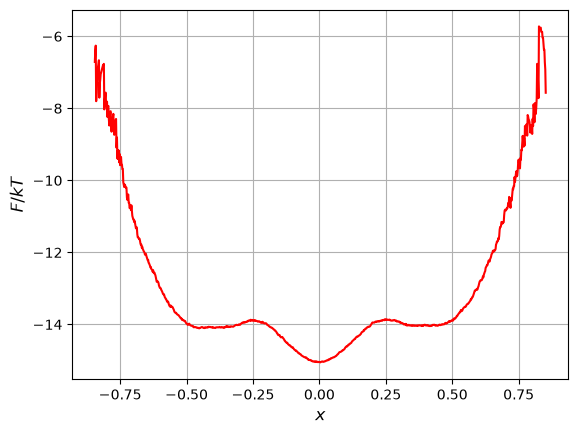

In [3]:
data = np.load(MD_FILE, mmap_mode='r')[:N_FRAMES]
lam, v = np.array(data[0][:, 0], dtype=float), np.array(data[0][:, 1], dtype=float)
lambda_a, lambda_b = LAMBDA_A, LAMBDA_B
boundary0, boundary1 = lam <= lambda_a, lam >= lambda_b
i_traj = np.ones(len(lam))                  # one trajectory
t_traj = np.arange(len(lam), dtype=float)   # frame index
print(f'{len(lam)} frames, v std {v.std():.3f}; frames in A {boundary0.mean():.3f}, in B {boundary1.mean():.3f}')
trans = (np.diff(boundary0.astype(int)) == 1).sum() + (np.diff(boundary1.astype(int)) == 1).sum()
print(f'entries into A or B: {trans}')
fig, ax = plt.subplots(1, 1)
plots.plot_fep(ax, cp.asarray(lam), xlabel='$x$')
plt.show()


## 4. Reference (optional)

In [4]:
if REF_FILE is None:
    q_exact = None
else:
    ref = np.load(REF_FILE)
    print(list(ref.keys()))
    f_ref = RegularGridInterpolator((ref['xs'], ref['vs']), ref['m'], bounds_error=False, fill_value=None)
    vv = v * V_SCALE
    q_exact = np.clip(f_ref(np.c_[np.clip(lam, ref['xs'][0], ref['xs'][-1]), np.clip(vv, ref['vs'][0], ref['vs'][-1])]), 0, 1)
free = (lam > lambda_a) & (lam < lambda_b)
edges_l = np.linspace(lambda_a, lambda_b, 71)
edges_v = np.linspace(*np.quantile(v[free], [0.002, 0.998]), 61)
n_lv = np.histogram2d(lam[free], v[free], [edges_l, edges_v])[0]


def make_q():
    return optimalrcs.CommittorNE(boundary0=boundary0, boundary1=boundary1, i_traj=i_traj, t_traj=t_traj)


def report(q):
    if q_exact is None:
        return ''
    r = cp.asnumpy(q.r_traj)
    return f'RMS(fit - reference) {np.sqrt(np.mean((r[free] - q_exact[free]) ** 2)):.4f}'


def qv_map(q):
    """mean q per (x, v) bin"""
    r = cp.asnumpy(q.r_traj)
    s = np.histogram2d(lam[free], v[free], [edges_l, edges_v], weights=r[free])[0]
    fig, ax = plt.subplots(figsize=(7, 5))
    im = ax.pcolormesh(edges_l, edges_v, np.where(n_lv > 20, s / np.maximum(n_lv, 1), np.nan).T, cmap='coolwarm', vmin=0, vmax=1)
    fig.colorbar(im, ax=ax, label='$q$'); ax.set(xlabel='$x$', ylabel='$v$')
    return fig


fits = {}


def run_variant(variant, cv_cols, history, max_iter):
    """Fit `variant` for every seed. CVs: columns cv_cols of (x, v), one drawn per iteration; history: lags (None: none)."""
    Y = cp.asarray(np.c_[lam, v * V_SCALE][:, cv_cols])
    kw = dict(ny=NY, print_step=min(CHUNK, 1000), save_min_delta_zq=False, lazy_basis=True)
    if history:
        kw.update(history_delta_t=list(history), history_type='y(t-d),y(t)')
    comp_y = lambda: Y[:, np.random.randint(Y.shape[1])]
    out = seed_runs.run_seeds(optimalrcs, make_q, comp_y, kw, SEEDS, max_iter, CHUNK, f'{OUT}/{variant}', ENVELOPE, GAMMA,
                              warmup_iter=WARMUP_ITER, warmup_envelope=WARMUP_ENVELOPE, warmup_gamma=GAMMA,
                              plots=('metrics', 'feps', 'obs_pred'), plot_options=dict(feps_kw=dict(delta_t_sim=DT_FRAME)),
                              extra_plot={'q_x_v': qv_map}, report=report)
    fits[variant] = out[0] if isinstance(out, tuple) else out
    return out


['xs', 'vs', 'm', 'A', 'B', 'c_map', 'dt', 'gamma', 'kT', 'm_previous', 'xs_previous', 'vs_previous', 'note']


## 5. Fits

Both fits use the same trajectory, seeds and settings, and differ in the CVs and the history. Plots go to `<OUT>/<variant>/seed<s>/it<N>_*.png`.

### 5a. Fit A: x only, with histories

#=1000, xent=0.393522, mse=0.137086, sdzq=119.3, dzq=322.021, dr2=3589.67, auc=0.877108, |dx|=0.204724, time=8.11162
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/history_x/seed0/it1000 ---


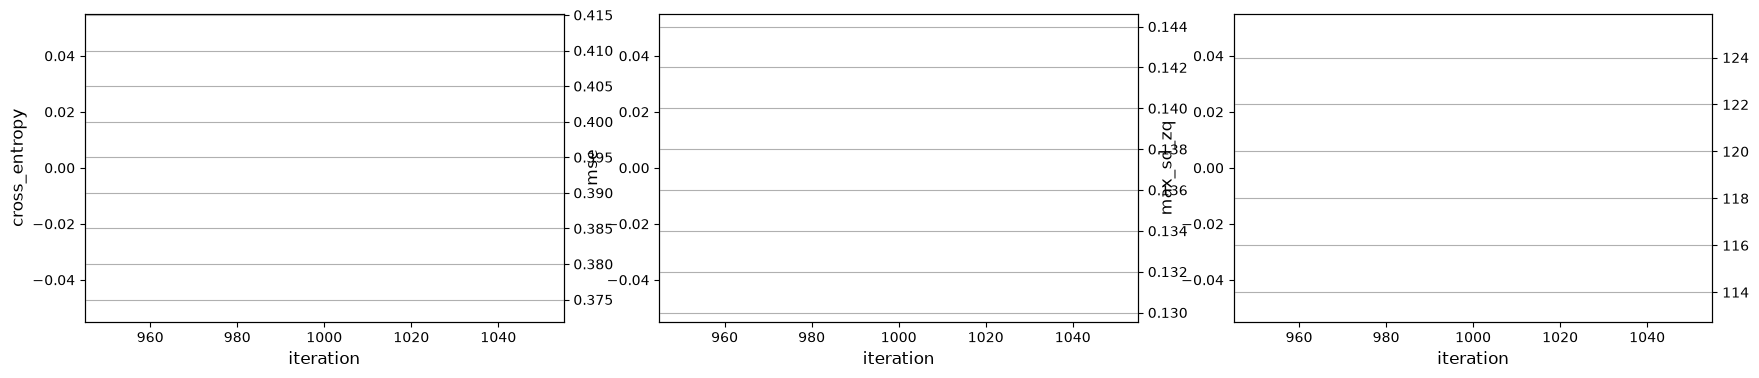

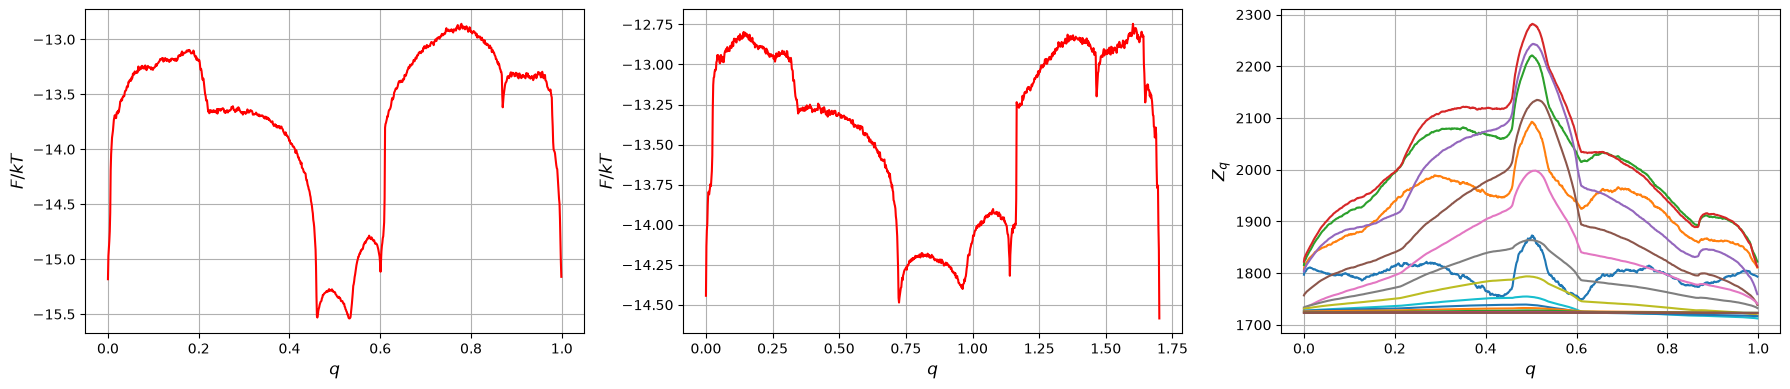

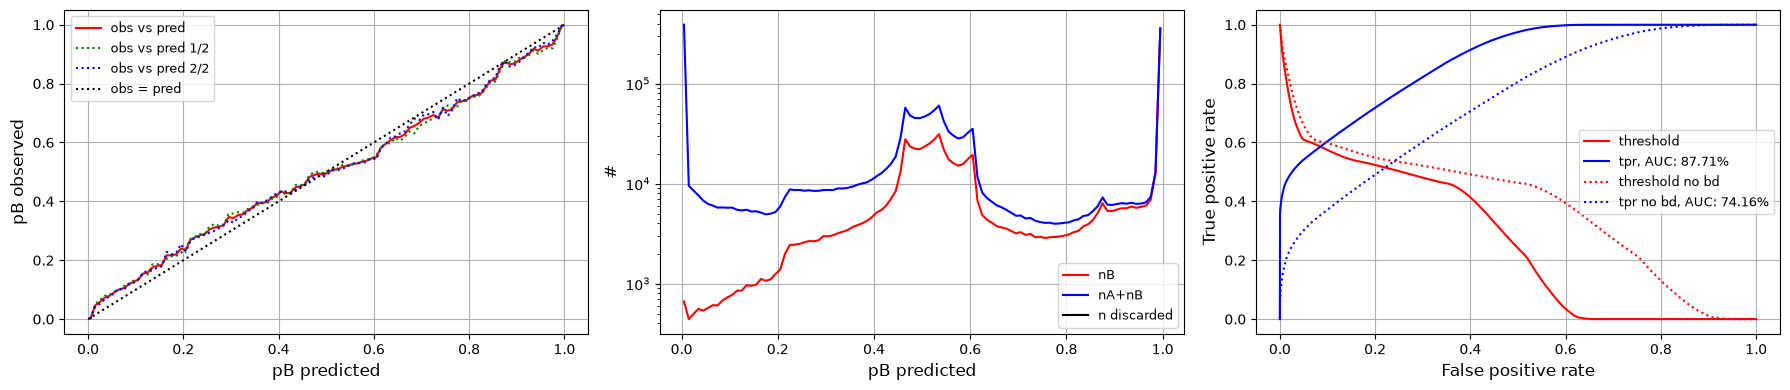

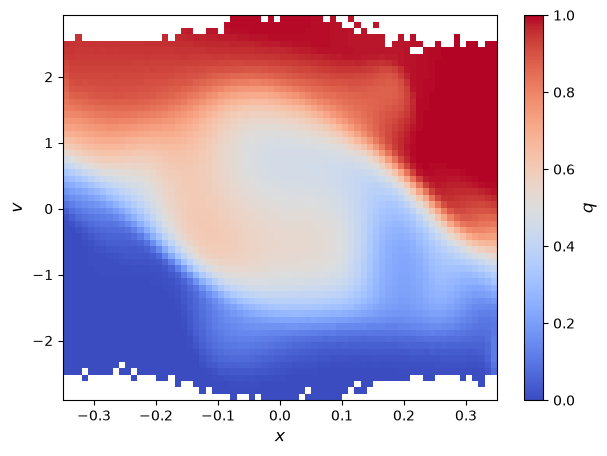

seed 0, 1000 iterations (warm-up: envelope 1, gamma 0.1) RMS(fit - reference) 0.0500
#=2000, xent=0.3904, mse=0.136357, sdzq=67.5811, dzq=162.35, dr2=3675.41, auc=0.877781, |dx|=0.0351855, time=7.60374
#=3000, xent=0.39025, mse=0.136296, sdzq=66.6727, dzq=159.384, dr2=3679.34, auc=0.877989, |dx|=0.00369034, time=15.2316
#=4000, xent=0.390222, mse=0.136274, sdzq=65.4932, dzq=157.394, dr2=3677.7, auc=0.878087, |dx|=0.00322552, time=22.843
#=5000, xent=0.390298, mse=0.136262, sdzq=65.6186, dzq=156.851, dr2=3678.91, auc=0.87815, |dx|=0.00161384, time=30.4587
#=6000, xent=0.390202, mse=0.13626, sdzq=65.3544, dzq=156.184, dr2=3678.3, auc=0.878192, |dx|=0.00181378, time=38.0674
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/history_x/seed0/it6000 ---


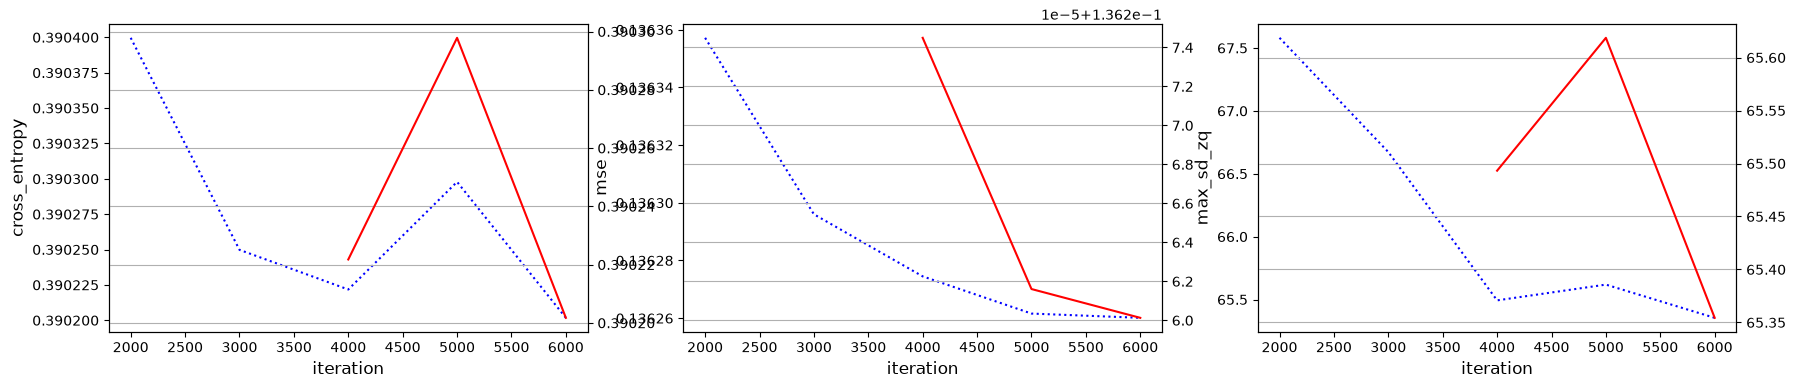

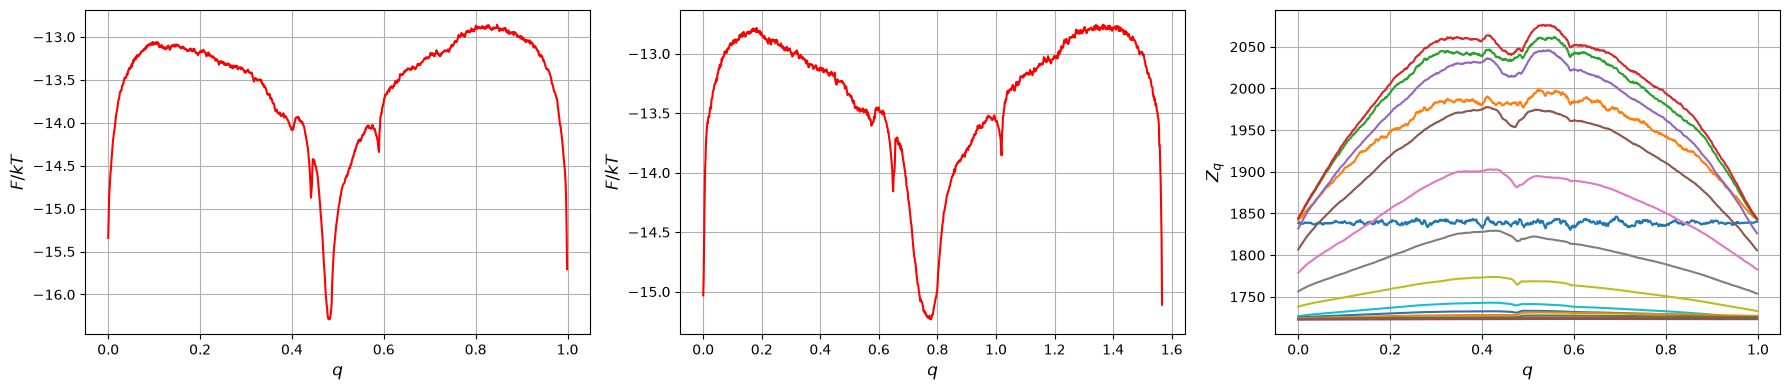

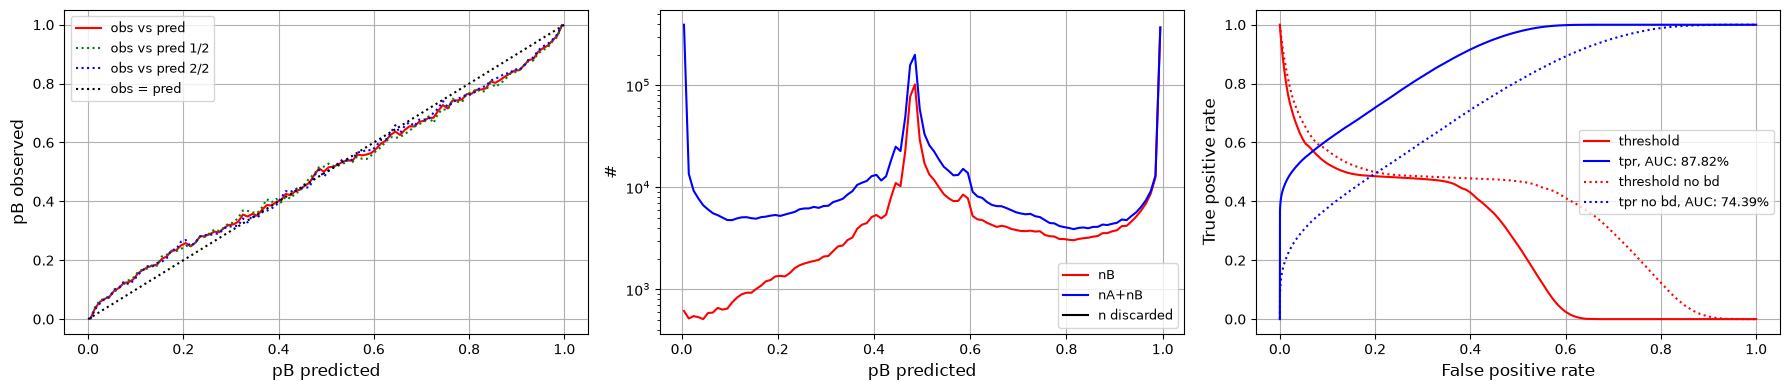

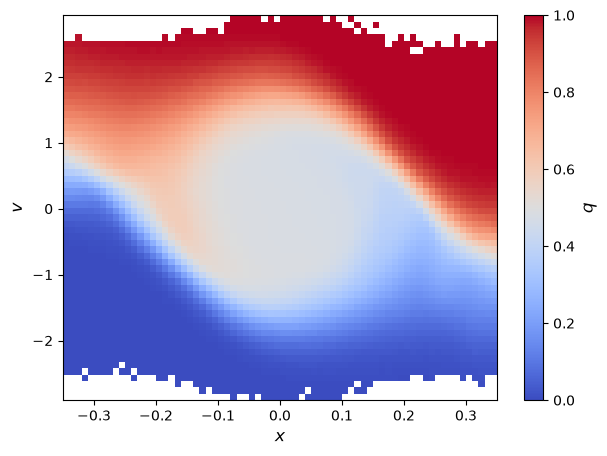

seed 0, 6000 iterations (main: envelope 0.01, gamma 0.1) RMS(fit - reference) 0.0337
#=7000, xent=0.390318, mse=0.136248, sdzq=65.0781, dzq=155.404, dr2=3678.86, auc=0.878215, |dx|=0.000916212, time=7.59829
#=8000, xent=0.390269, mse=0.136239, sdzq=64.2701, dzq=153.626, dr2=3674.78, auc=0.878241, |dx|=0.00134013, time=15.213
#=9000, xent=0.390235, mse=0.136233, sdzq=64.5066, dzq=153.714, dr2=3671.3, auc=0.878263, |dx|=0.00103117, time=22.8232
#=10000, xent=0.390309, mse=0.136232, sdzq=64.67, dzq=154.151, dr2=3672.34, auc=0.878273, |dx|=0.000734345, time=30.4176
#=11000, xent=0.390193, mse=0.136228, sdzq=64.4964, dzq=153.698, dr2=3671.9, auc=0.878279, |dx|=0.000773925, time=38.0214
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/history_x/seed0/it11000 ---


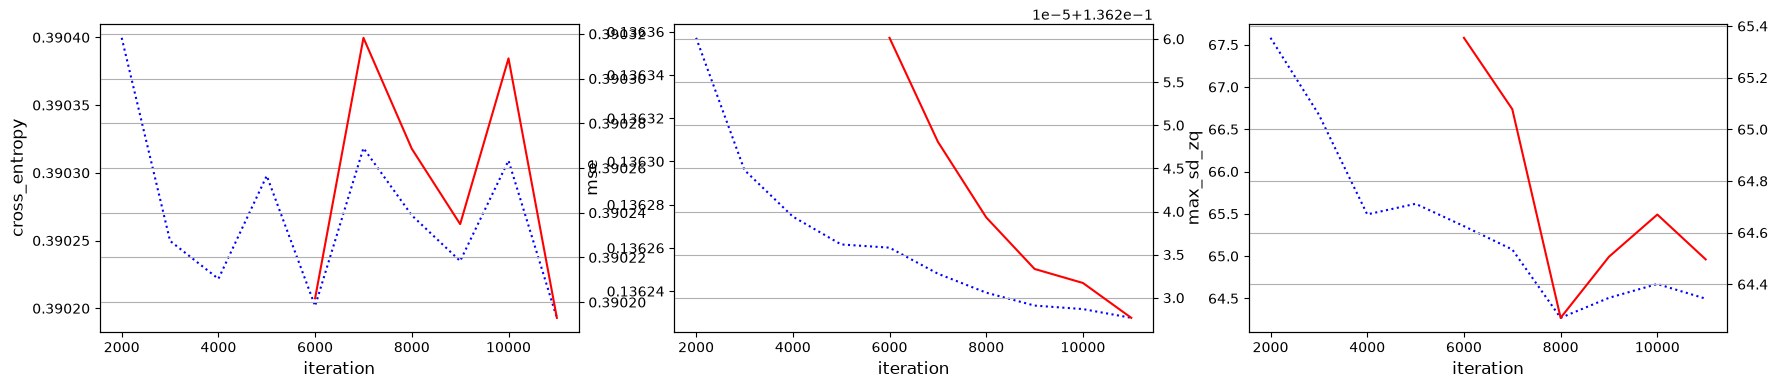

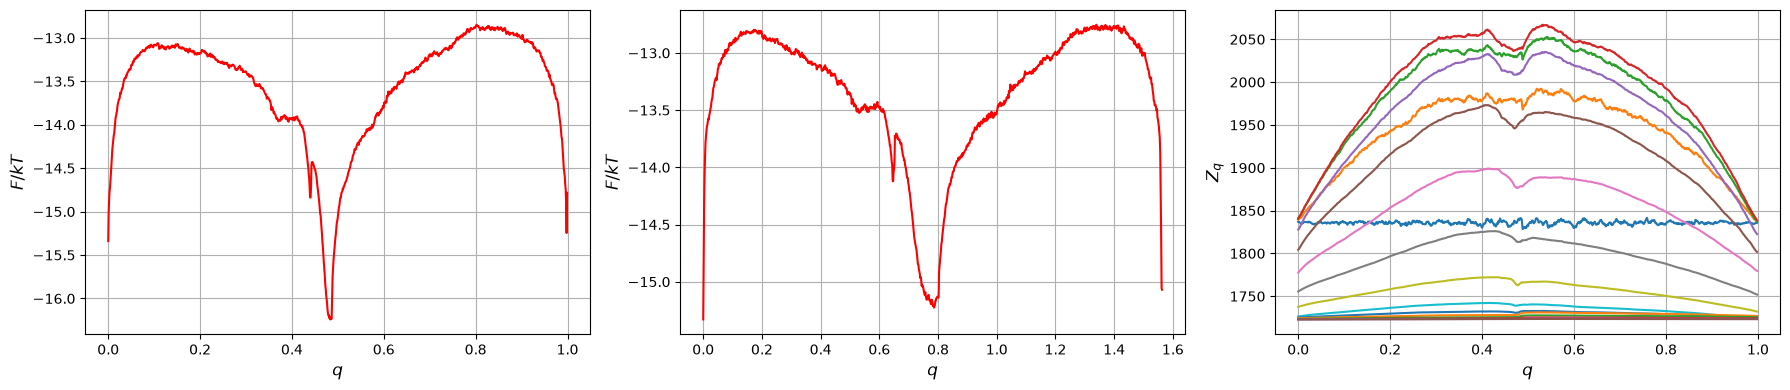

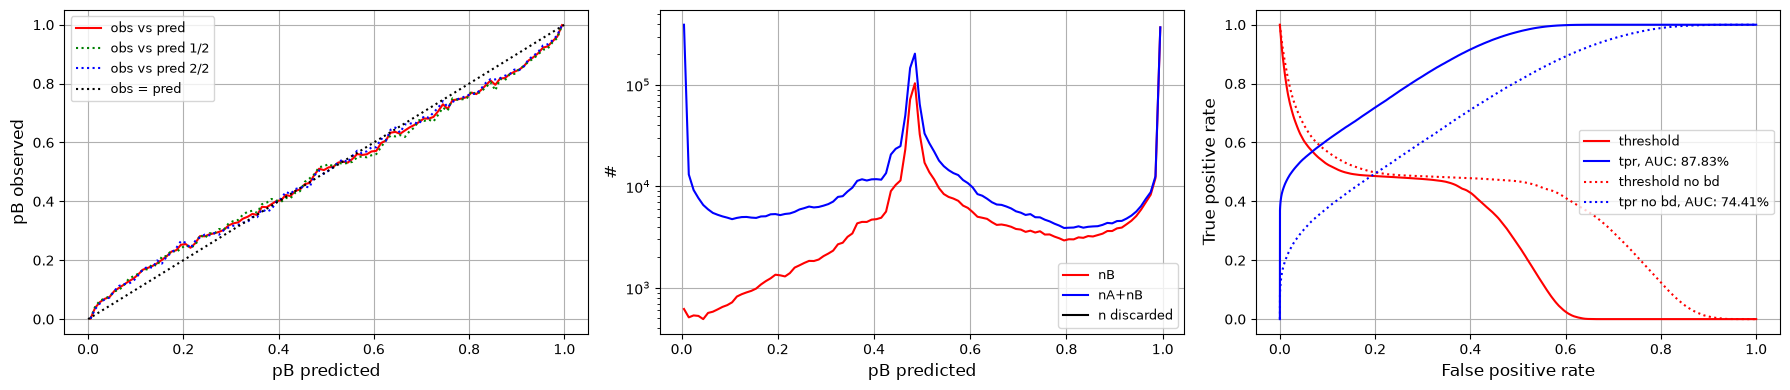

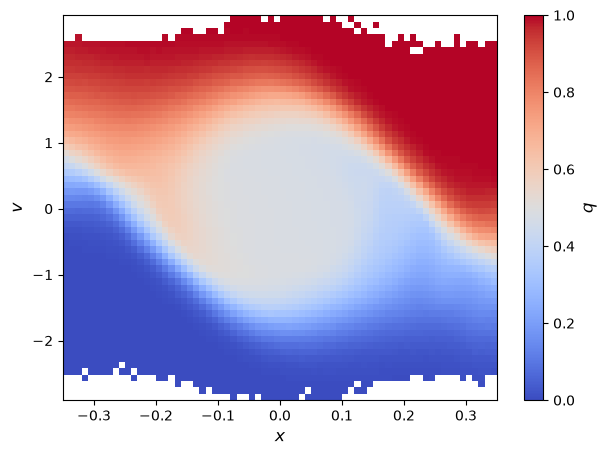

seed 0, 11000 iterations (main: envelope 0.01, gamma 0.1) RMS(fit - reference) 0.0334
seed 0: RMS(fit - reference) 0.0334


({0: {'r': array([0.50588874, 0.47349237, 0.47349174, ..., 0.3489785 , 0.3768951 ,
          0.43621296], shape=(2000000,)),
   'report': 'RMS(fit - reference) 0.0334'}},
 <optimalrcs.CommittorNE at 0x7fc1601ad400>)

In [17]:
run_variant('history_x', [0], HISTORY, MAX_ITER_HIST)


#=1000, xent=0.388329, mse=0.135969, sdzq=29.206, dzq=158.701, dr2=3497.91, auc=0.878138, |dx|=0.193942, time=5.74577
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/x_v/seed1/it1000 ---


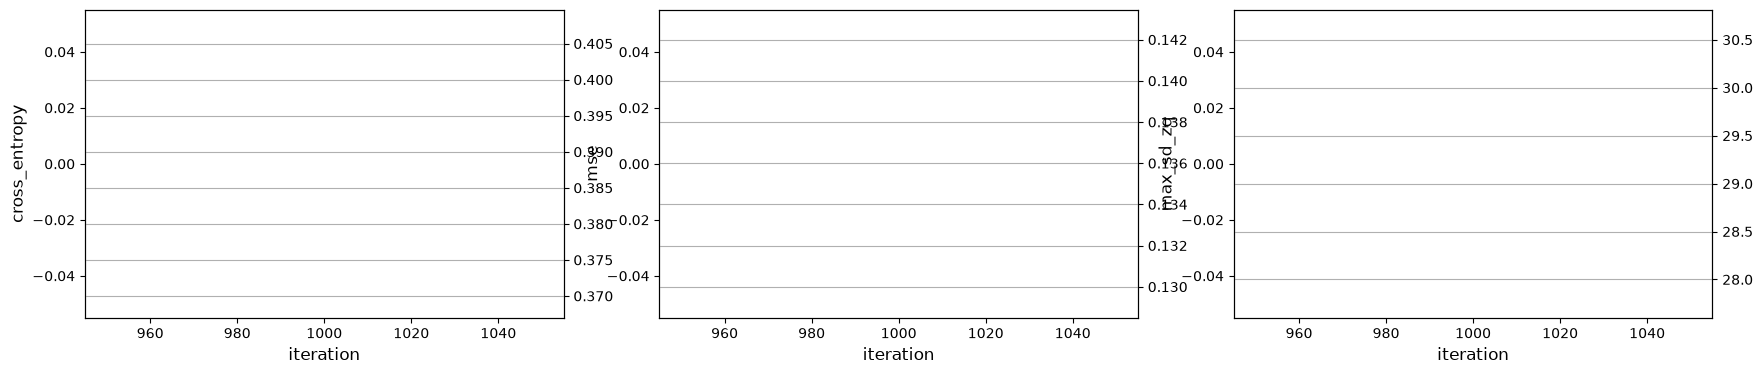

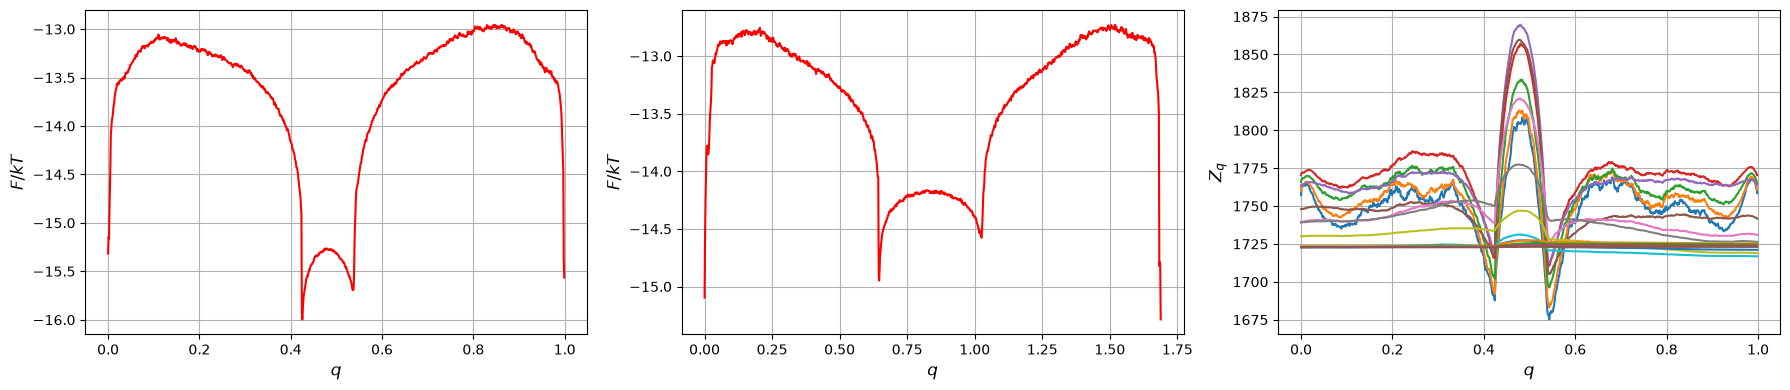

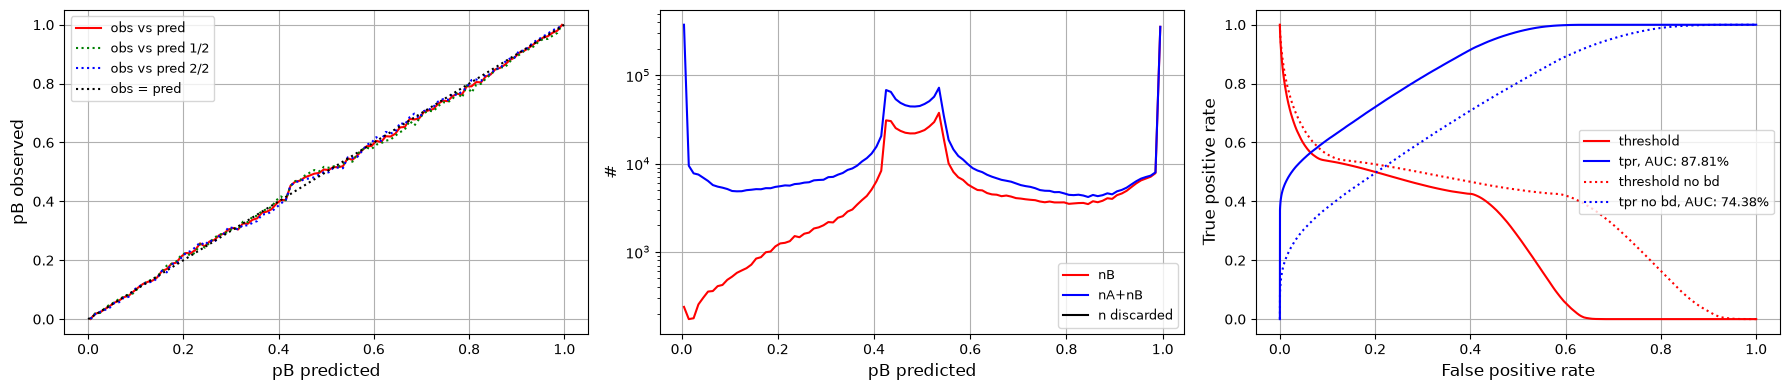

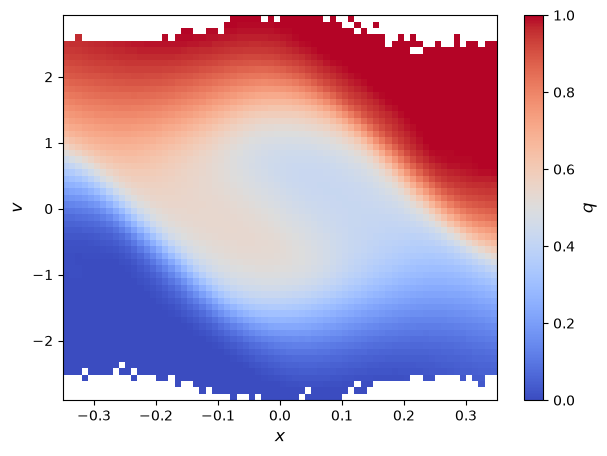

seed 1, 1000 iterations (warm-up: envelope 1, gamma 0.1) RMS(fit - reference) 0.0283
#=2000, xent=0.387531, mse=0.135696, sdzq=6.67798, dzq=15.0091, dr2=3496.81, auc=0.878824, |dx|=0.01583, time=5.70073
#=3000, xent=0.3875, mse=0.135687, sdzq=6.93052, dzq=14.4907, dr2=3489.63, auc=0.878841, |dx|=0.00154327, time=11.4112
#=4000, xent=0.387503, mse=0.135682, sdzq=6.49683, dzq=13.9187, dr2=3483.95, auc=0.878851, |dx|=0.0008505, time=17.1377
#=5000, xent=0.387474, mse=0.135677, sdzq=6.63328, dzq=13.2942, dr2=3483.27, auc=0.878863, |dx|=0.000696458, time=22.862
#=6000, xent=0.387473, mse=0.135676, sdzq=6.48555, dzq=13.4359, dr2=3482.51, auc=0.878864, |dx|=0.00039396, time=28.5938
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/x_v/seed1/it6000 ---


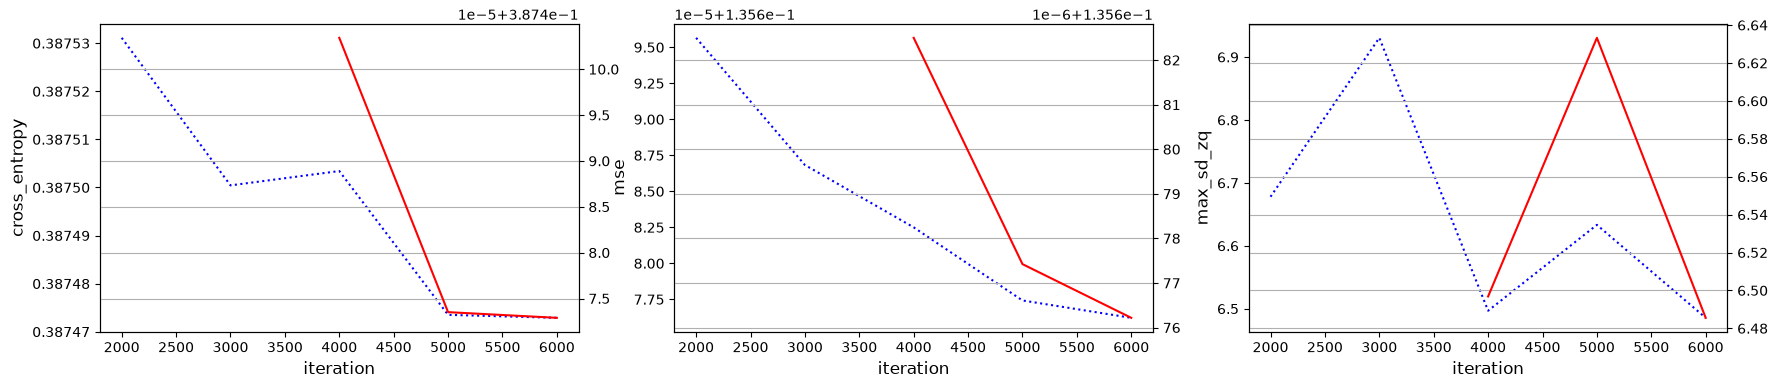

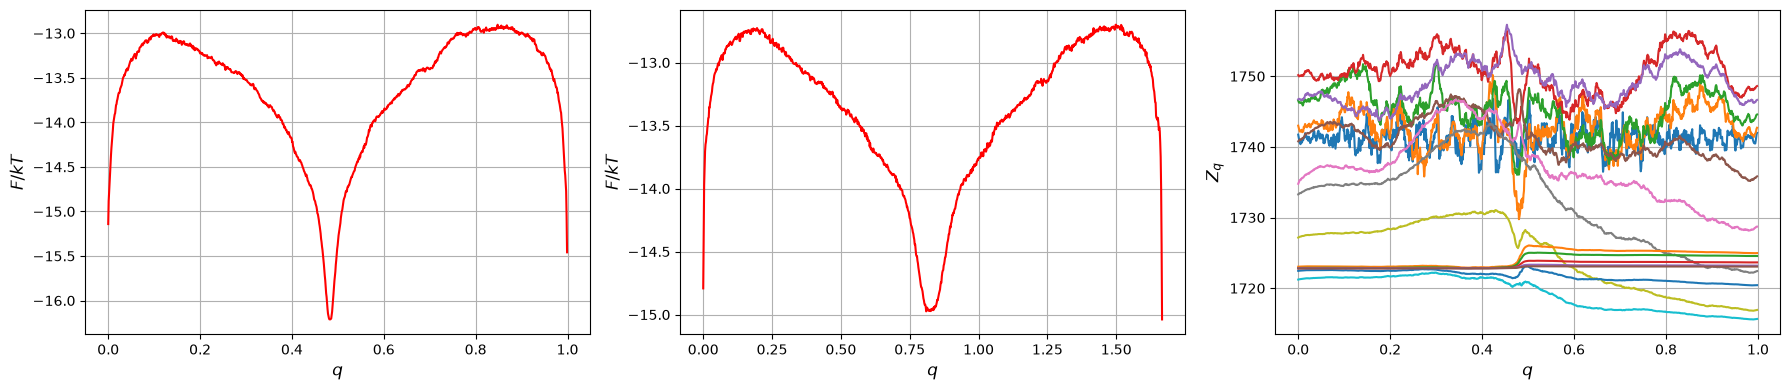

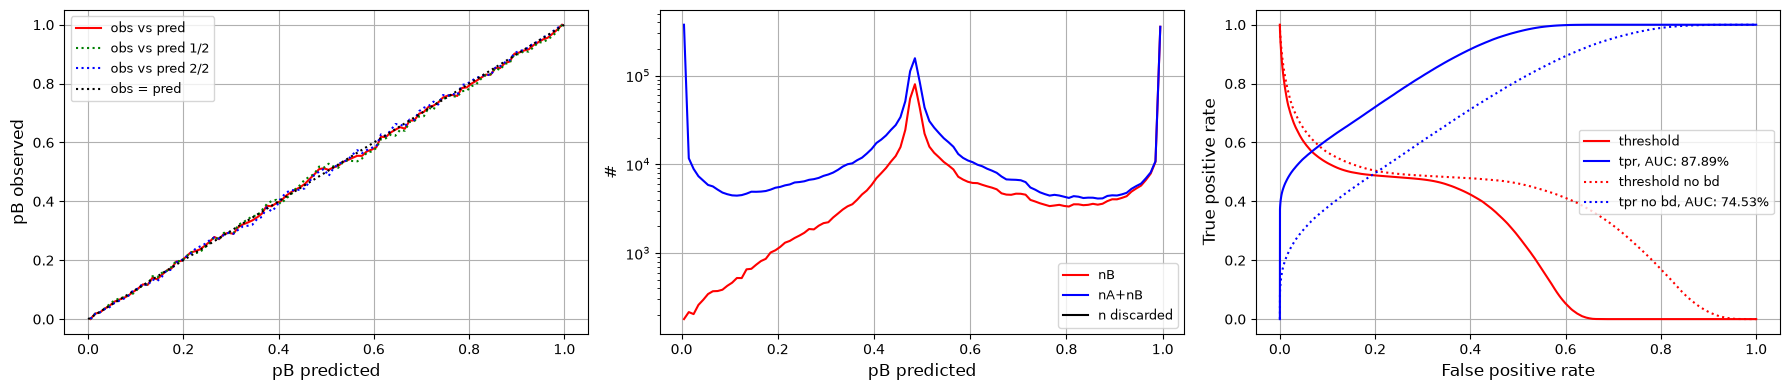

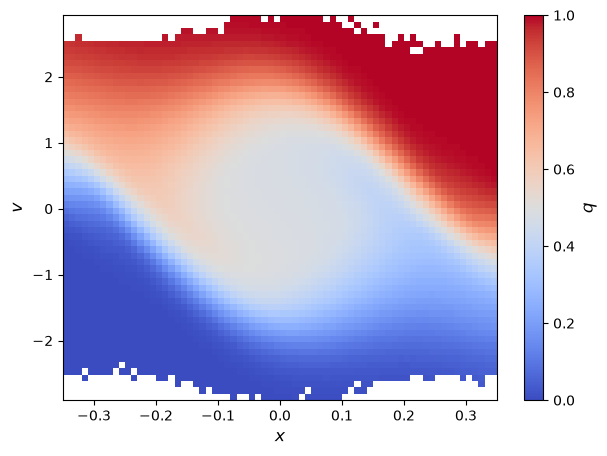

seed 1, 6000 iterations (main: envelope 0.01, gamma 0.1) RMS(fit - reference) 0.0180
#=7000, xent=0.387476, mse=0.135677, sdzq=6.44065, dzq=13.077, dr2=3482.39, auc=0.878865, |dx|=0.000262485, time=5.7239
#=8000, xent=0.387473, mse=0.135675, sdzq=6.45634, dzq=12.9819, dr2=3481.06, auc=0.878868, |dx|=0.000277575, time=11.4564
#=9000, xent=0.387472, mse=0.135675, sdzq=6.45014, dzq=13.0471, dr2=3481.17, auc=0.878869, |dx|=0.000242518, time=17.1895
#=10000, xent=0.387479, mse=0.135676, sdzq=6.41802, dzq=12.7482, dr2=3480.51, auc=0.878863, |dx|=0.000252775, time=22.9191
#=11000, xent=0.387475, mse=0.135674, sdzq=6.32861, dzq=12.7123, dr2=3480.31, auc=0.878872, |dx|=0.000250839, time=28.66
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/x_v/seed1/it11000 ---


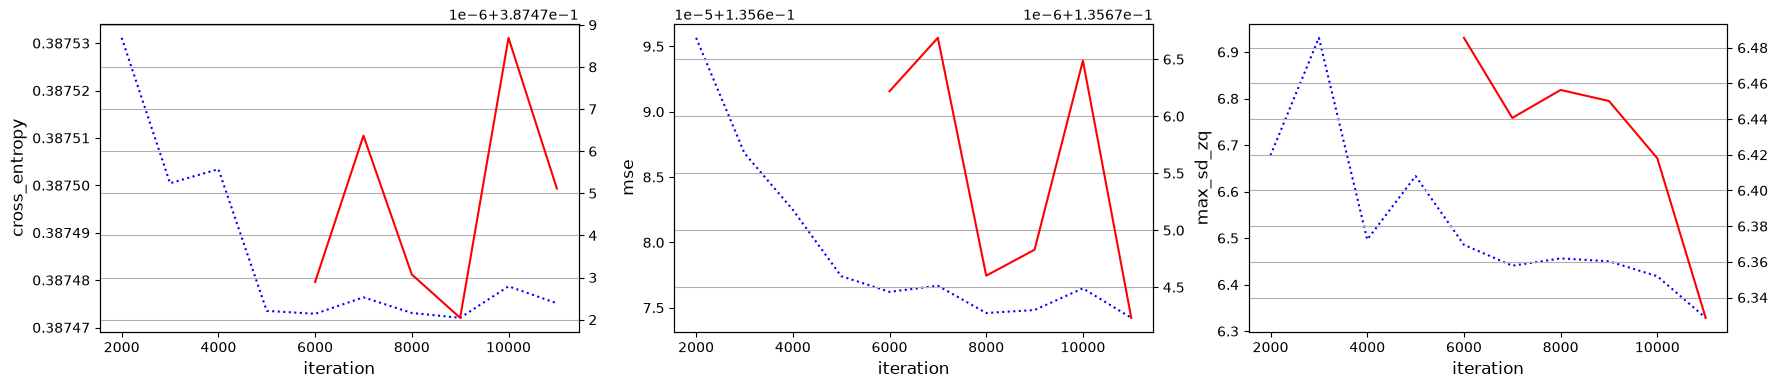

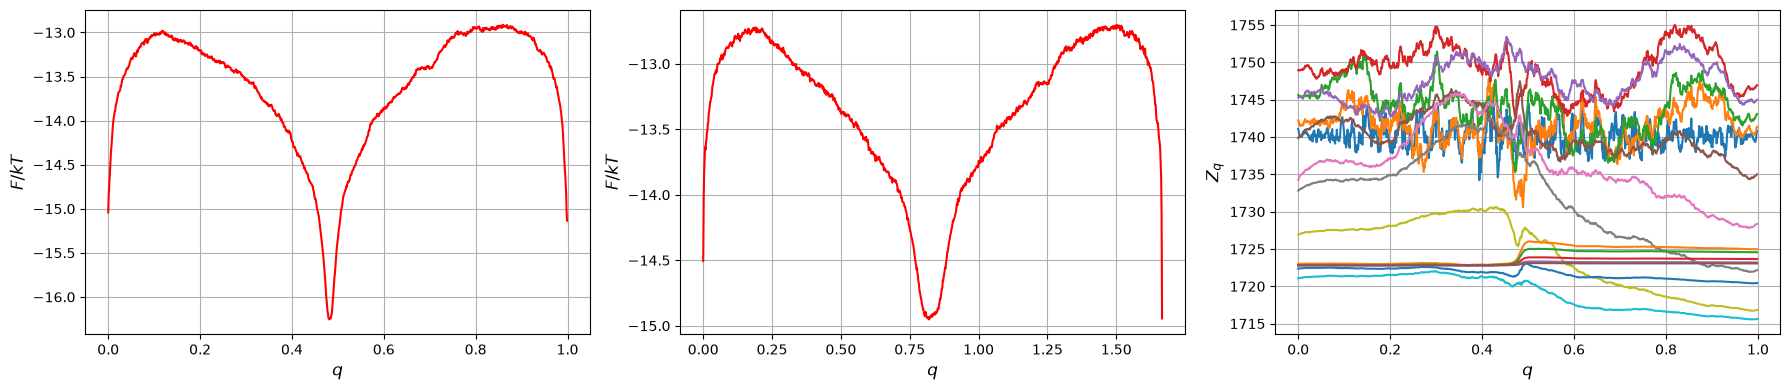

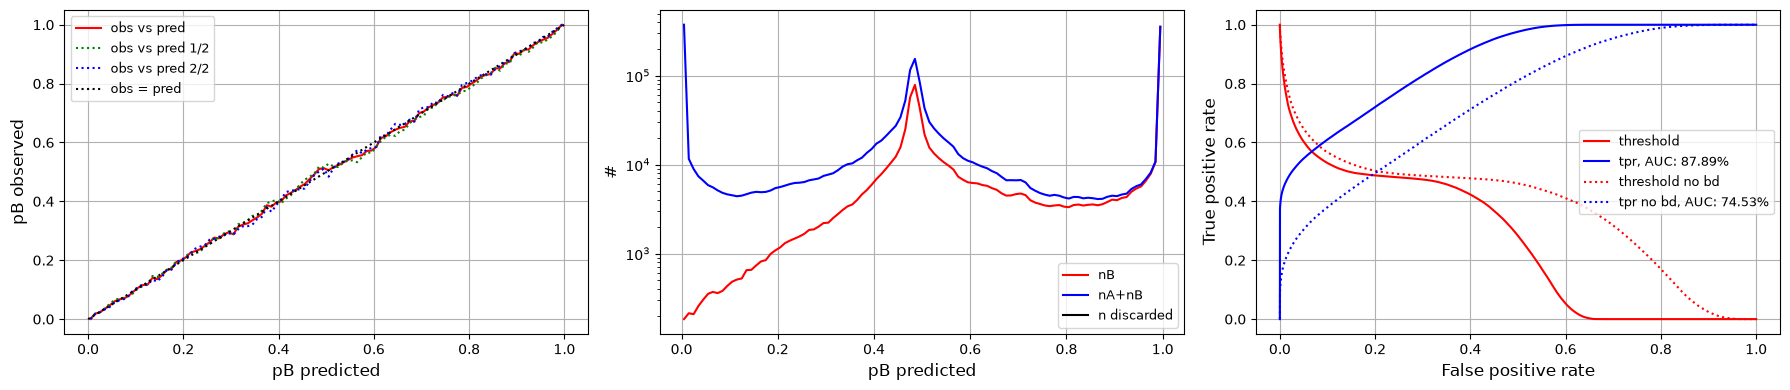

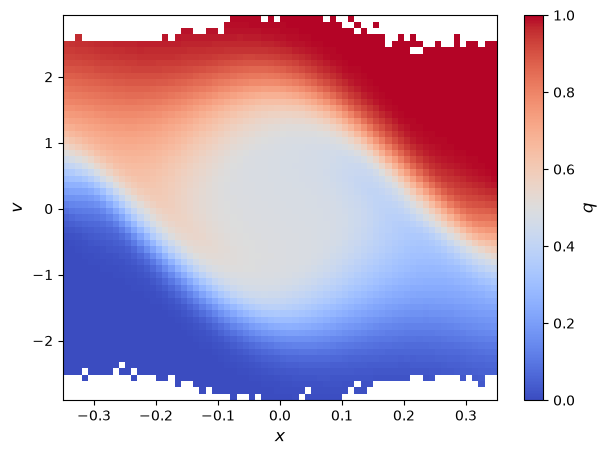

seed 1, 11000 iterations (main: envelope 0.01, gamma 0.1) RMS(fit - reference) 0.0179
#=1000, xent=0.393584, mse=0.138297, sdzq=73.1577, dzq=323.493, dr2=3041.15, auc=0.872646, |dx|=0.180299, time=5.78235
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/x_v/seed2/it1000 ---


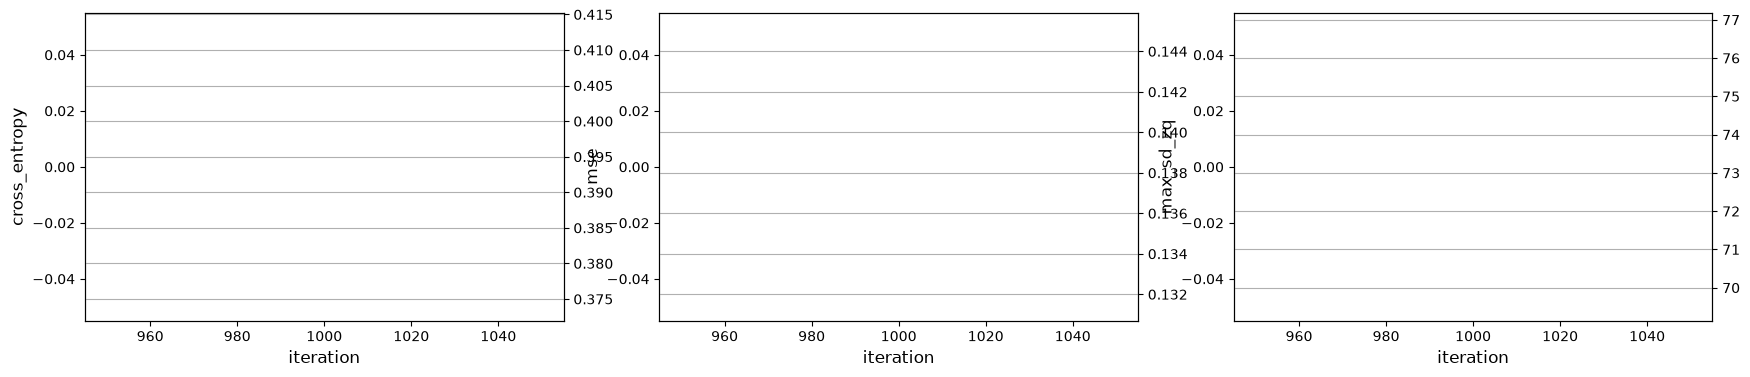

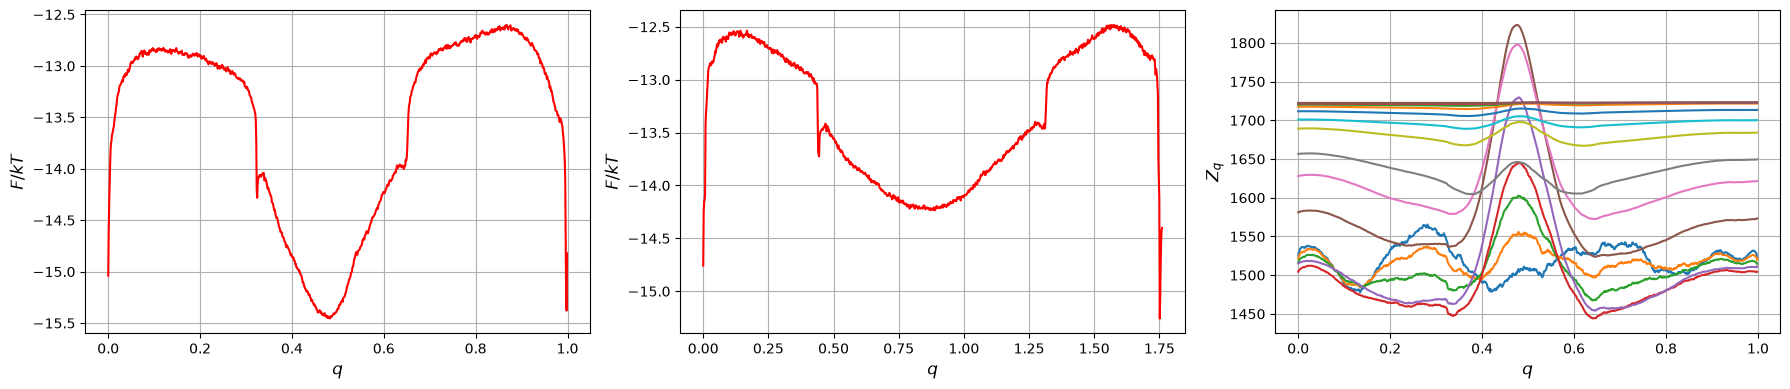

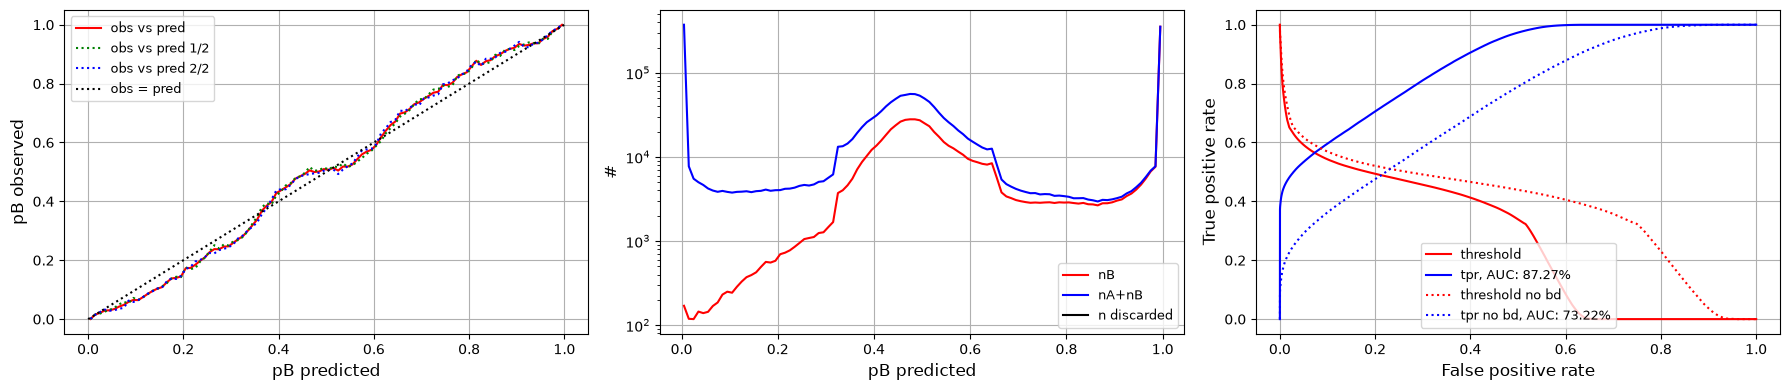

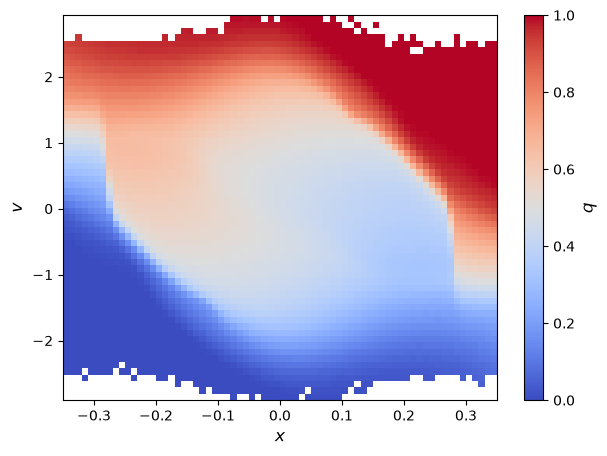

seed 2, 1000 iterations (warm-up: envelope 1, gamma 0.1) RMS(fit - reference) 0.0653
#=2000, xent=0.390324, mse=0.136942, sdzq=33.8043, dzq=154.763, dr2=3214.42, auc=0.875399, |dx|=0.0210527, time=5.73804
#=3000, xent=0.390208, mse=0.136884, sdzq=32.2689, dzq=152.797, dr2=3214.62, auc=0.875545, |dx|=0.00302902, time=11.4785
#=4000, xent=0.39005, mse=0.136818, sdzq=30.5579, dzq=145.019, dr2=3221.84, auc=0.875693, |dx|=0.0023078, time=17.2187
#=5000, xent=0.390058, mse=0.13682, sdzq=29.9314, dzq=144.258, dr2=3217.87, auc=0.875696, |dx|=0.00202948, time=22.958
#=6000, xent=0.389898, mse=0.136747, sdzq=29.7138, dzq=144.009, dr2=3214.35, auc=0.875909, |dx|=0.00378395, time=28.6827
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/x_v/seed2/it6000 ---


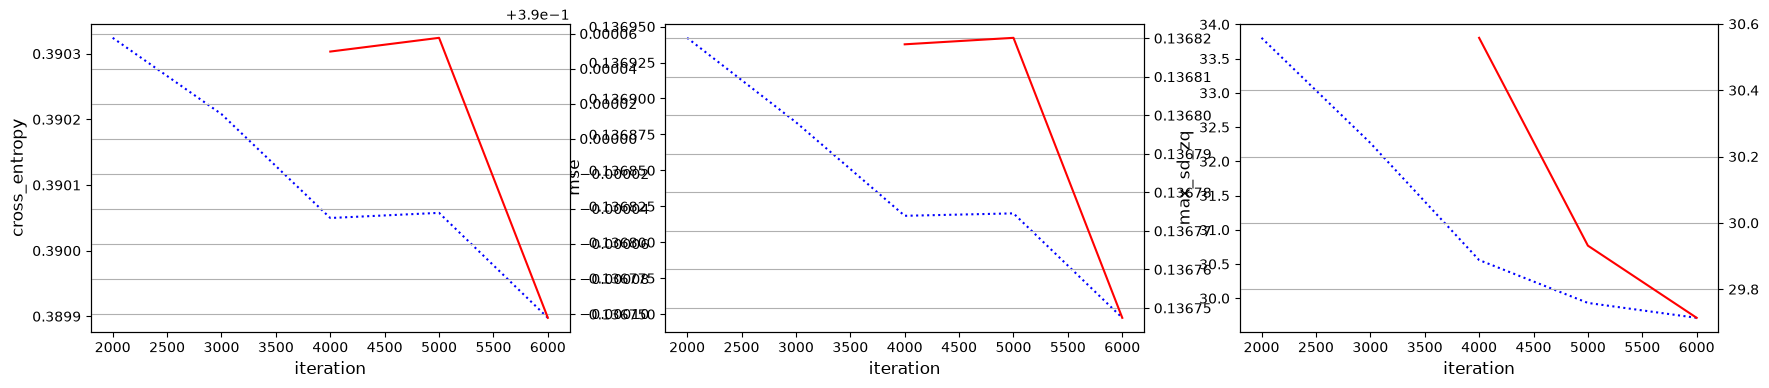

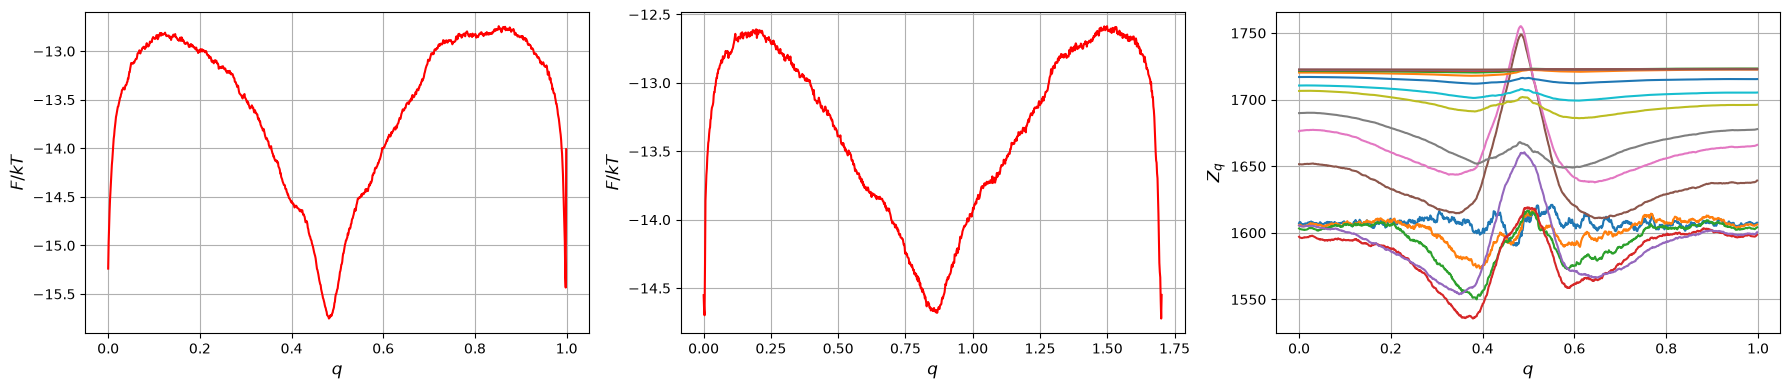

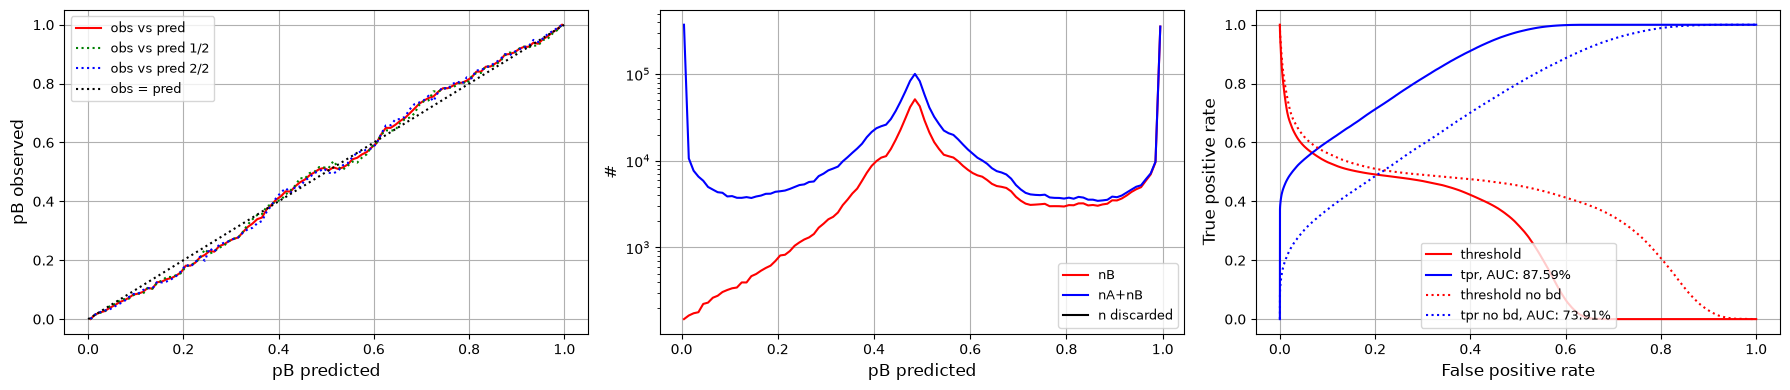

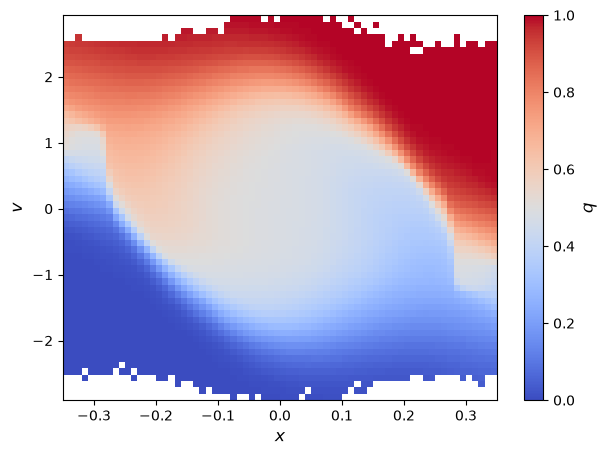

seed 2, 6000 iterations (main: envelope 0.01, gamma 0.1) RMS(fit - reference) 0.0442
#=7000, xent=0.389858, mse=0.136738, sdzq=27.0964, dzq=131.963, dr2=3227.87, auc=0.875897, |dx|=0.00293412, time=5.72303
#=8000, xent=0.38984, mse=0.136725, sdzq=26.0073, dzq=126.901, dr2=3230.23, auc=0.875917, |dx|=0.00118663, time=11.4535
#=9000, xent=0.389837, mse=0.136723, sdzq=26.5967, dzq=130.275, dr2=3230.2, auc=0.875941, |dx|=0.000741619, time=17.1904
#=10000, xent=0.38982, mse=0.13672, sdzq=26.8999, dzq=131.518, dr2=3229.82, auc=0.875956, |dx|=0.000557401, time=22.9205
#=11000, xent=0.389817, mse=0.13672, sdzq=27.8894, dzq=135.692, dr2=3226.24, auc=0.875941, |dx|=0.00103725, time=28.65
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/x_v/seed2/it11000 ---


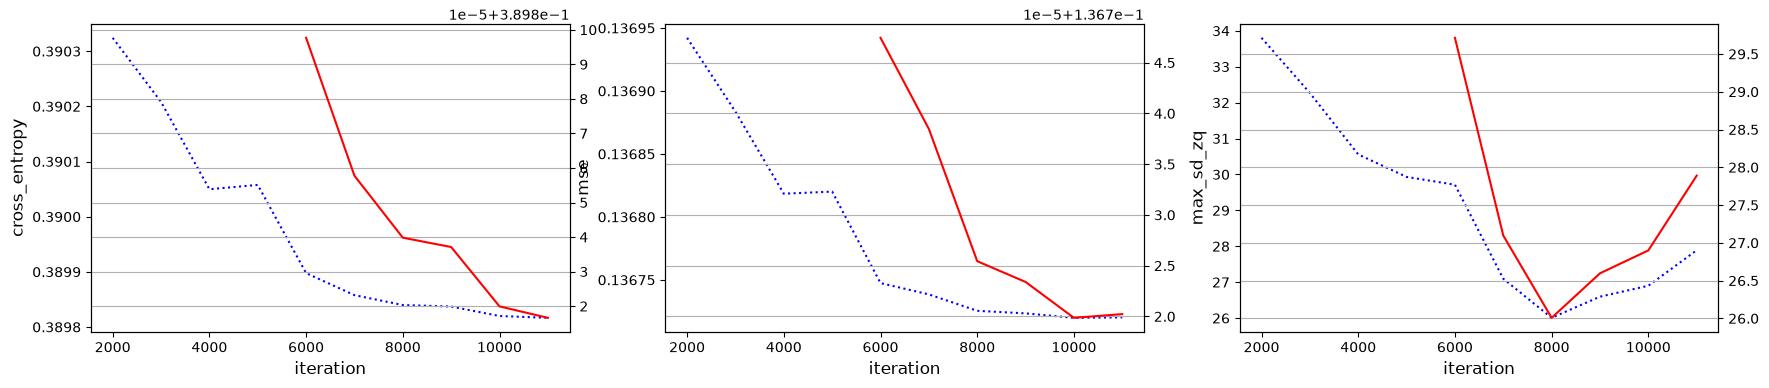

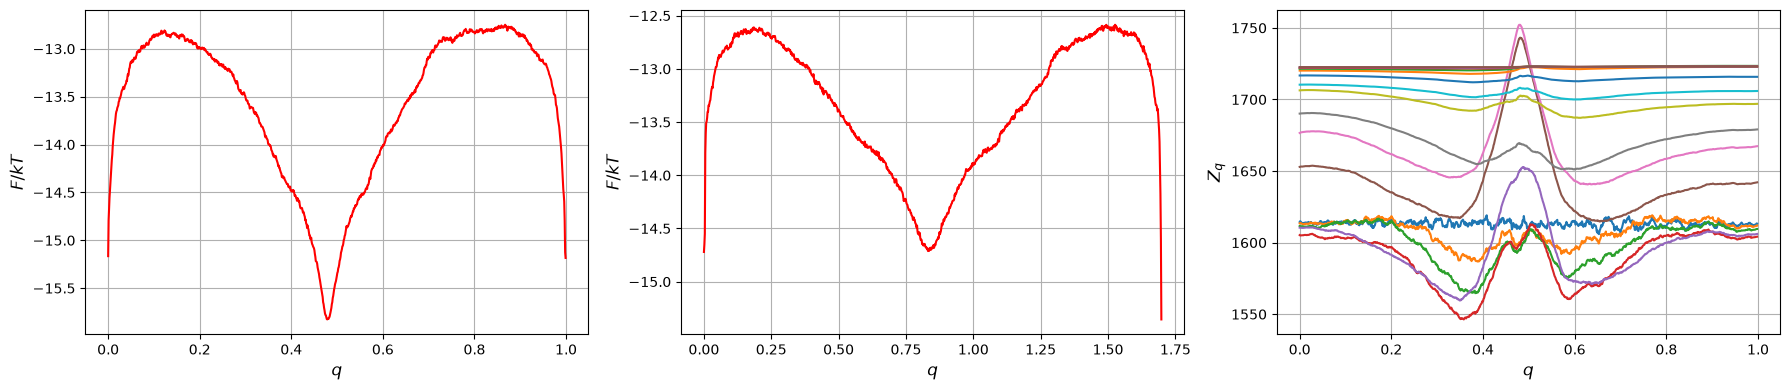

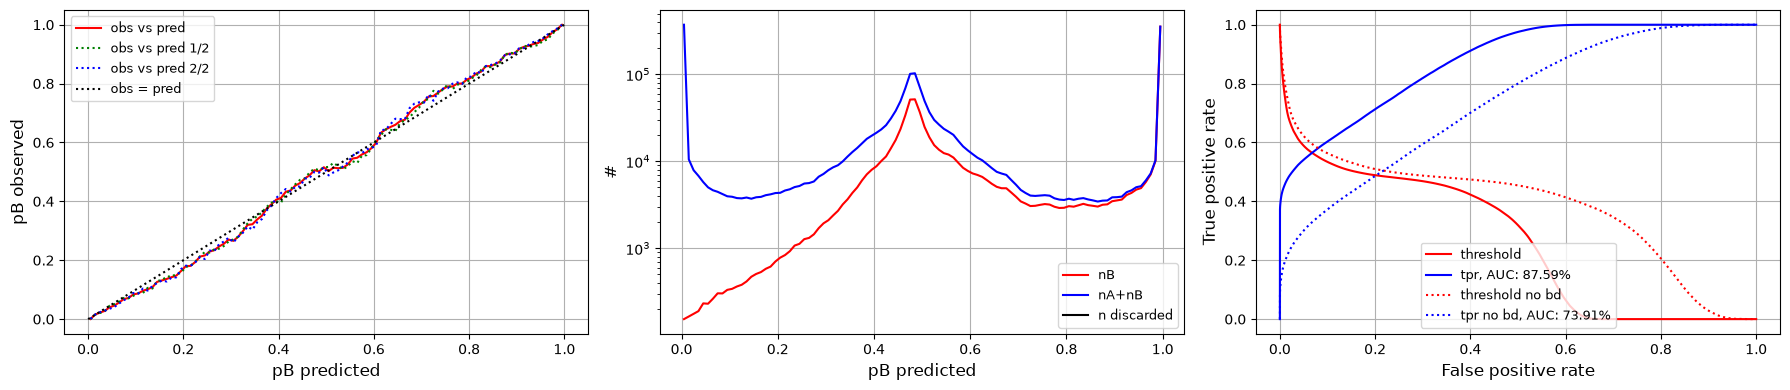

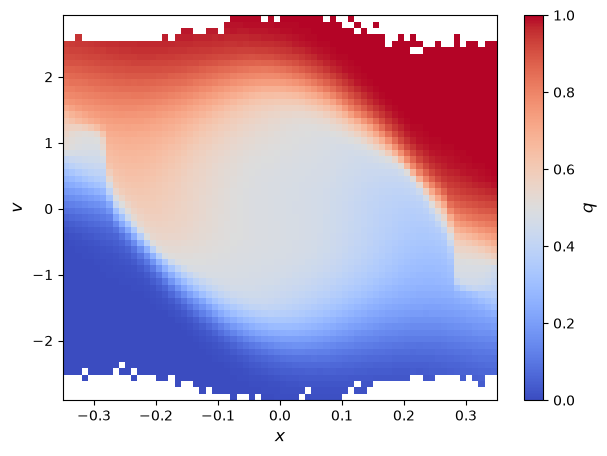

seed 2, 11000 iterations (main: envelope 0.01, gamma 0.1) RMS(fit - reference) 0.0437
#=1000, xent=0.396282, mse=0.139334, sdzq=93.3489, dzq=382.649, dr2=2946.58, auc=0.87051, |dx|=0.177402, time=5.76307
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/x_v/seed3/it1000 ---


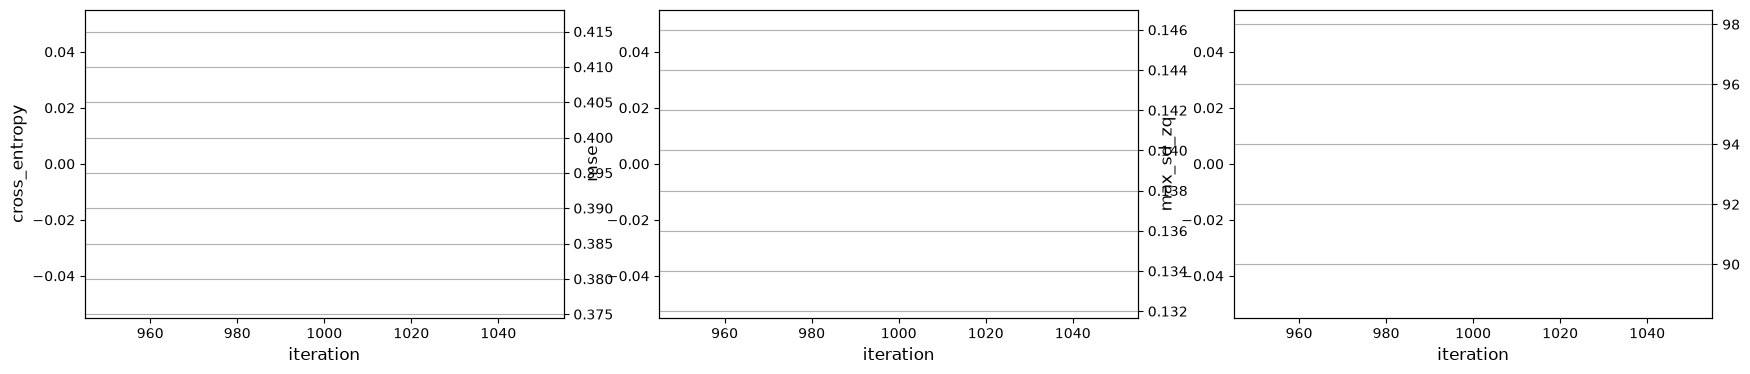

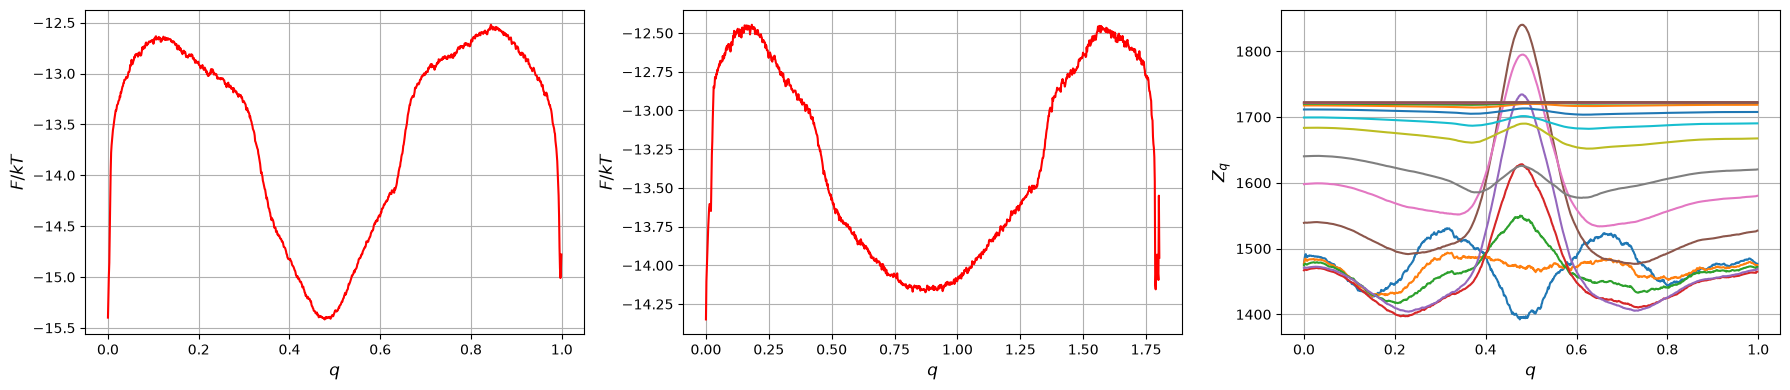

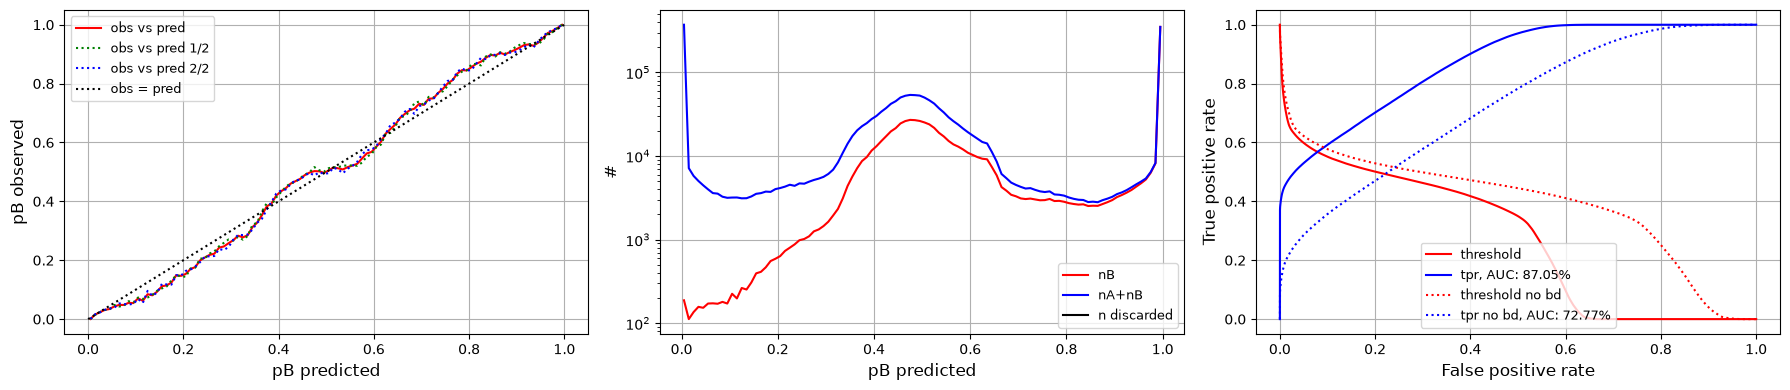

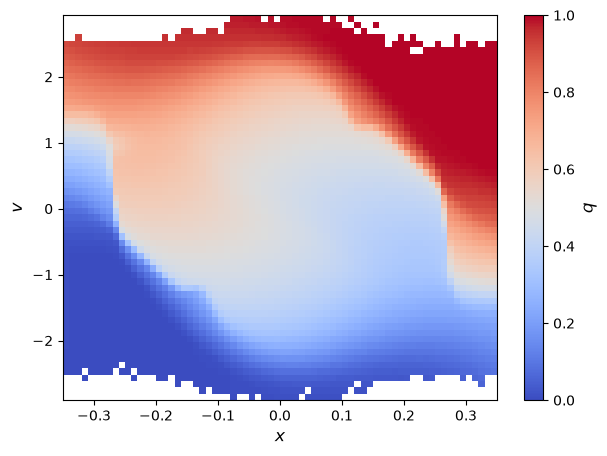

seed 3, 1000 iterations (warm-up: envelope 1, gamma 0.1) RMS(fit - reference) 0.0753
#=2000, xent=0.391135, mse=0.137258, sdzq=41.7339, dzq=183.85, dr2=3170.47, auc=0.874535, |dx|=0.0282083, time=5.72944
#=3000, xent=0.390804, mse=0.137123, sdzq=40.4413, dzq=184.358, dr2=3185.09, auc=0.874866, |dx|=0.00454737, time=11.4617
#=4000, xent=0.390596, mse=0.137049, sdzq=37.4513, dzq=176.442, dr2=3183.81, auc=0.87502, |dx|=0.00333833, time=17.1937
#=5000, xent=0.390568, mse=0.137049, sdzq=36.0402, dzq=174.683, dr2=3186.62, auc=0.875001, |dx|=0.00470544, time=22.9302
#=6000, xent=0.390429, mse=0.136981, sdzq=34.925, dzq=168.384, dr2=3195.13, auc=0.875162, |dx|=0.00224708, time=28.6712
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/x_v/seed3/it6000 ---


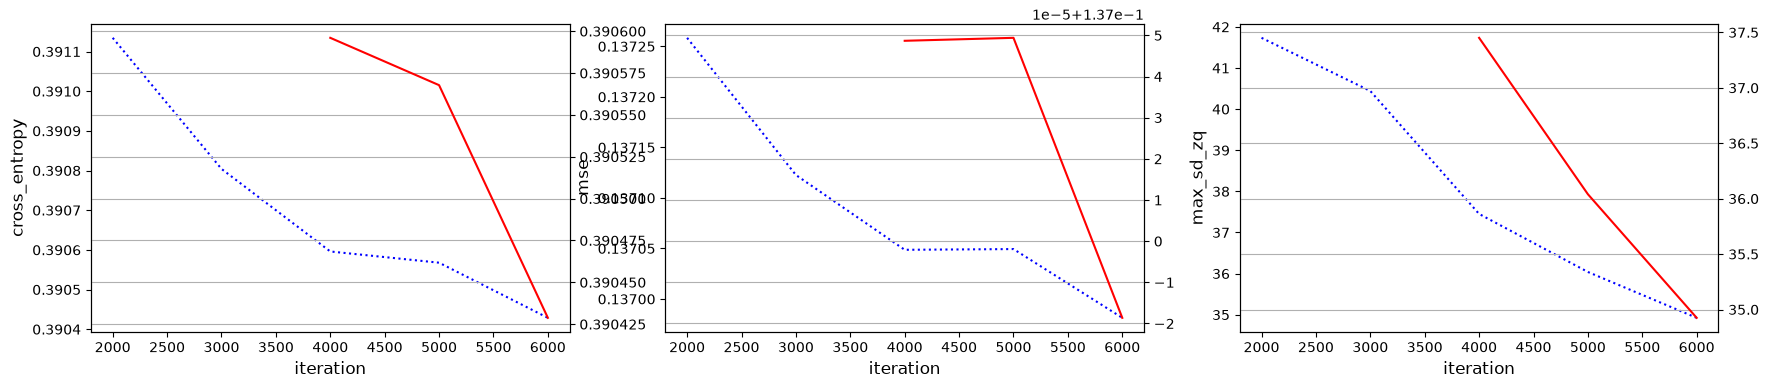

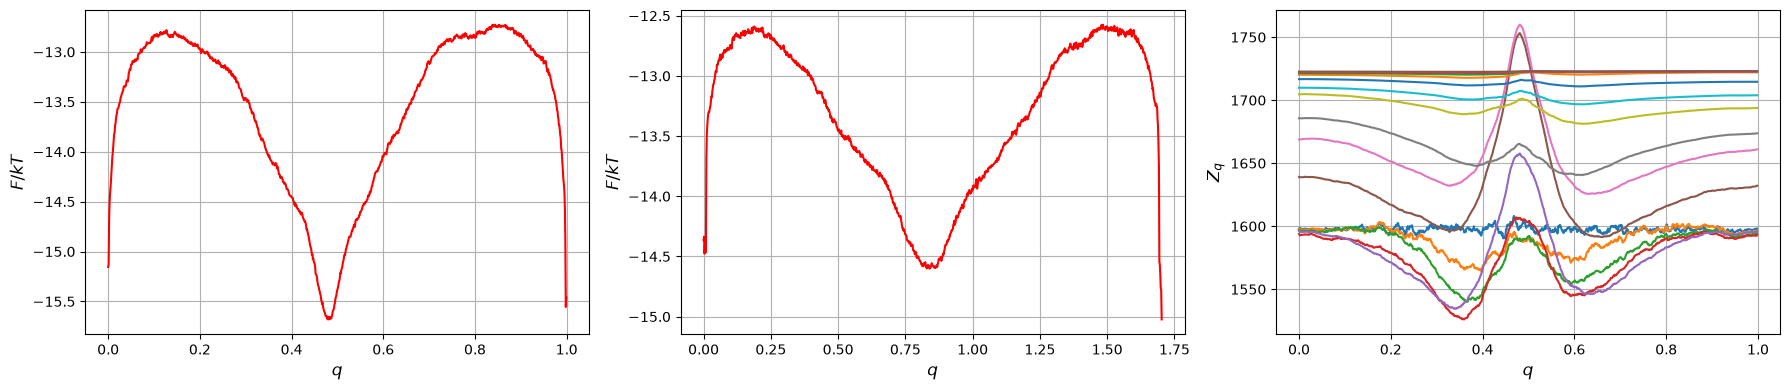

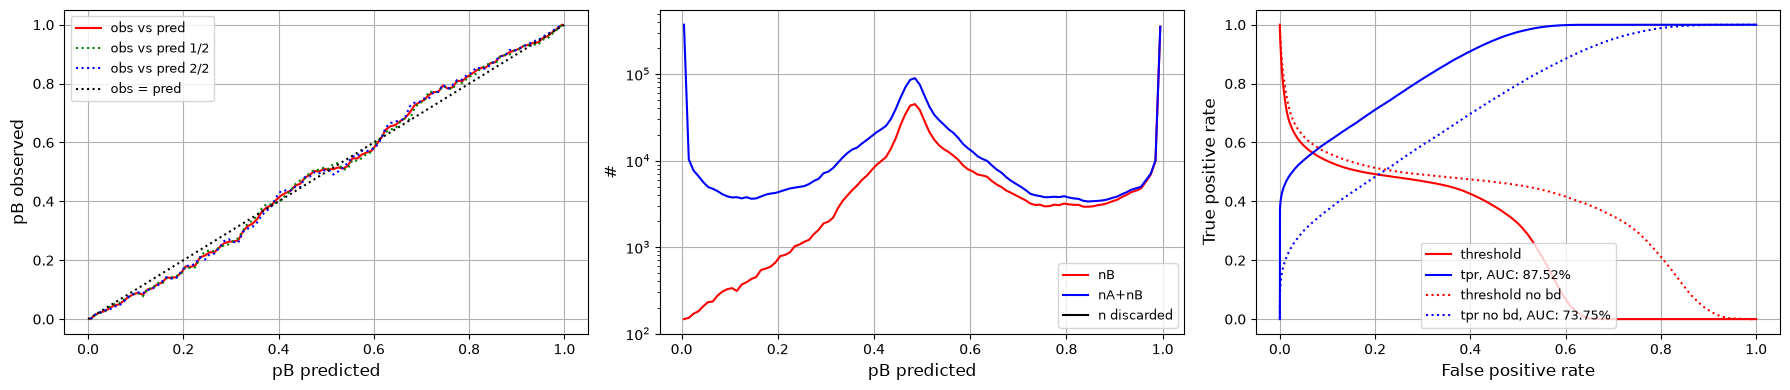

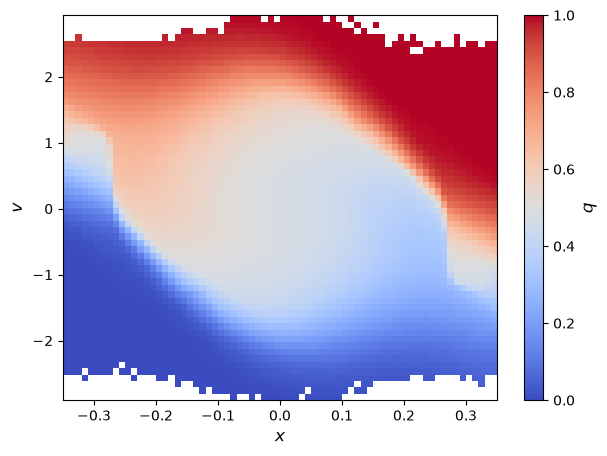

seed 3, 6000 iterations (main: envelope 0.01, gamma 0.1) RMS(fit - reference) 0.0474
#=7000, xent=0.39042, mse=0.136985, sdzq=32.2381, dzq=156.96, dr2=3203.89, auc=0.875163, |dx|=0.00348228, time=5.7067
#=8000, xent=0.390135, mse=0.136846, sdzq=29.021, dzq=142.655, dr2=3208.47, auc=0.875487, |dx|=0.0070347, time=11.4173
#=9000, xent=0.390137, mse=0.136857, sdzq=32.189, dzq=157.448, dr2=3205.51, auc=0.875443, |dx|=0.0035958, time=17.1251
#=10000, xent=0.390124, mse=0.13686, sdzq=33.0646, dzq=162.465, dr2=3199.62, auc=0.875415, |dx|=0.00188438, time=22.8521
#=11000, xent=0.390116, mse=0.136855, sdzq=31.6922, dzq=156.21, dr2=3206.31, auc=0.875428, |dx|=0.00158209, time=28.5531
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/x_v/seed3/it11000 ---


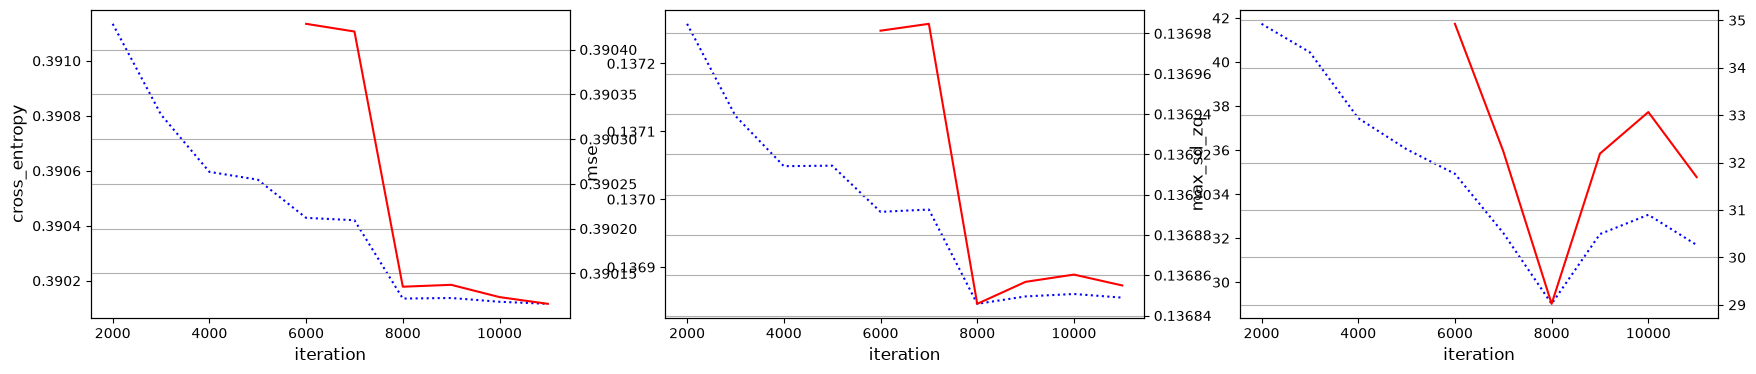

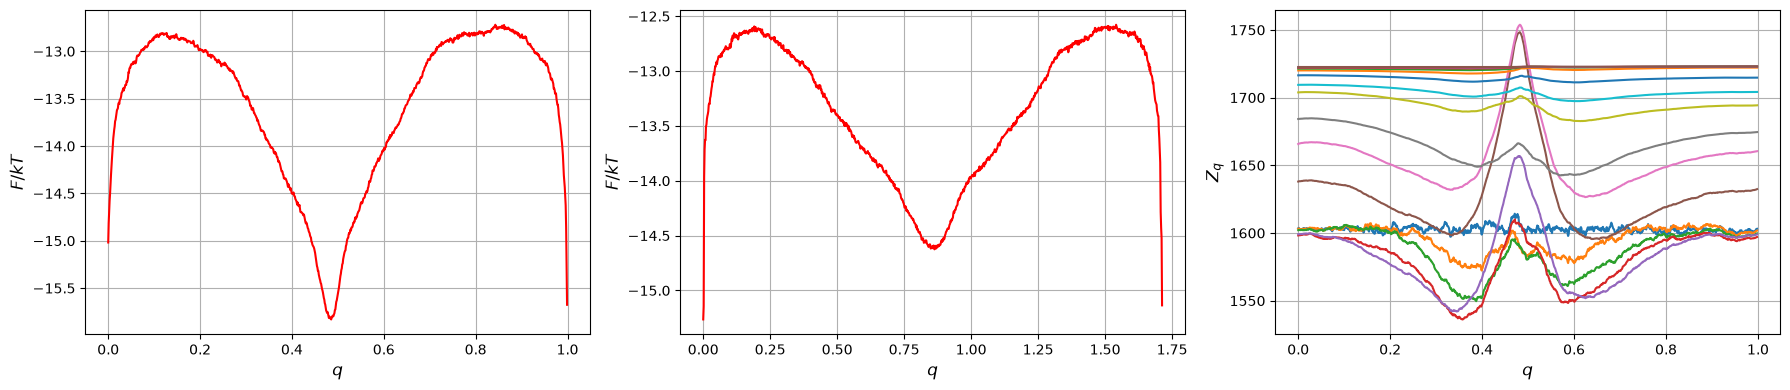

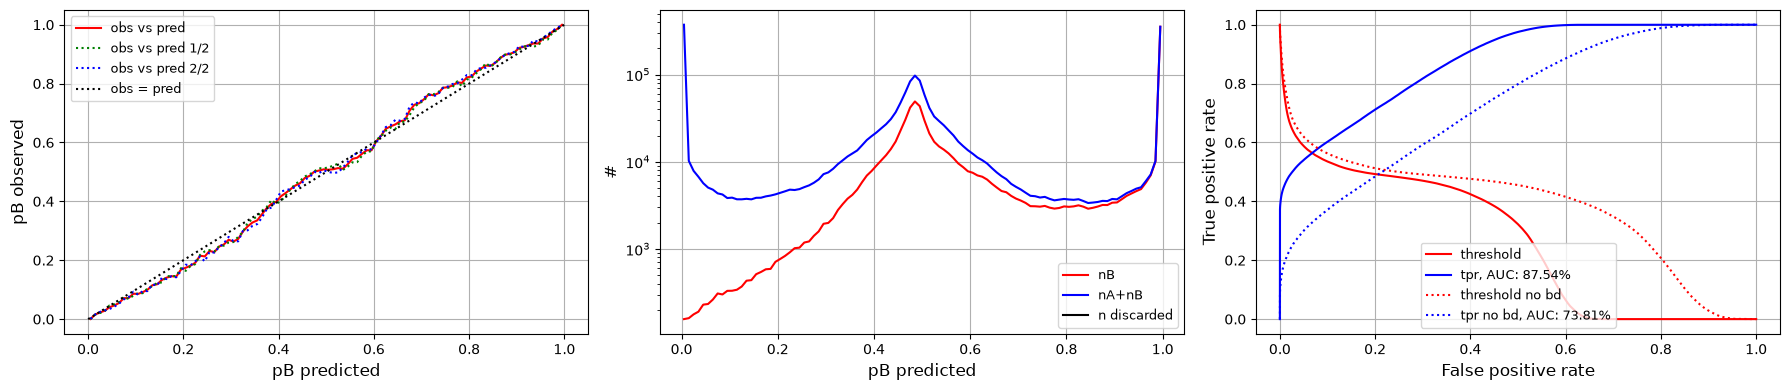

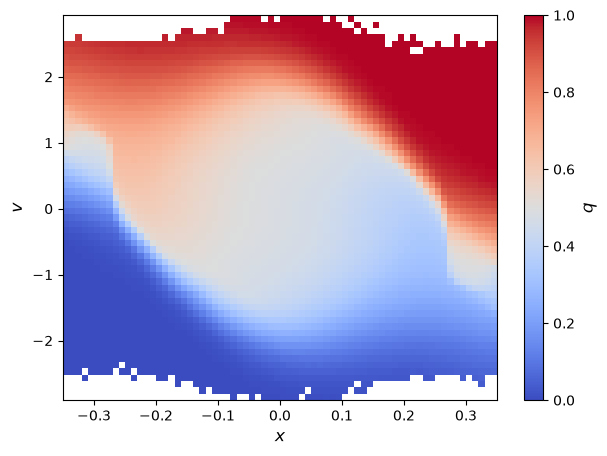

seed 3, 11000 iterations (main: envelope 0.01, gamma 0.1) RMS(fit - reference) 0.0457
seed 1: RMS(fit - reference) 0.0179
seed 2: RMS(fit - reference) 0.0437
seed 3: RMS(fit - reference) 0.0457


({1: {'r': array([0.46843846, 0.46869316, 0.47017283, ..., 0.38637122, 0.38905348,
          0.45354542], shape=(2000000,)),
   'report': 'RMS(fit - reference) 0.0179'},
  2: {'r': array([0.46316575, 0.46208594, 0.46038942, ..., 0.39762993, 0.40114509,
          0.43982935], shape=(2000000,)),
   'report': 'RMS(fit - reference) 0.0437'},
  3: {'r': array([0.46697171, 0.46566117, 0.46326789, ..., 0.40492504, 0.40866508,
          0.44268691], shape=(2000000,)),
   'report': 'RMS(fit - reference) 0.0457'}},
 <optimalrcs.CommittorNE at 0x7fe5ef73c490>)

In [9]:
run_variant('x_v', [0,1], False, MAX_ITER_XV)


### 5b. Fit B: x and v as CVs, no history

#=1000, xent=0.393661, mse=0.137934, sdzq=115.912, dzq=371.482, dr2=3620.62, auc=0.875021, |dx|=0.201677, time=5.79569
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/history_x5/seed1/it1000 ---


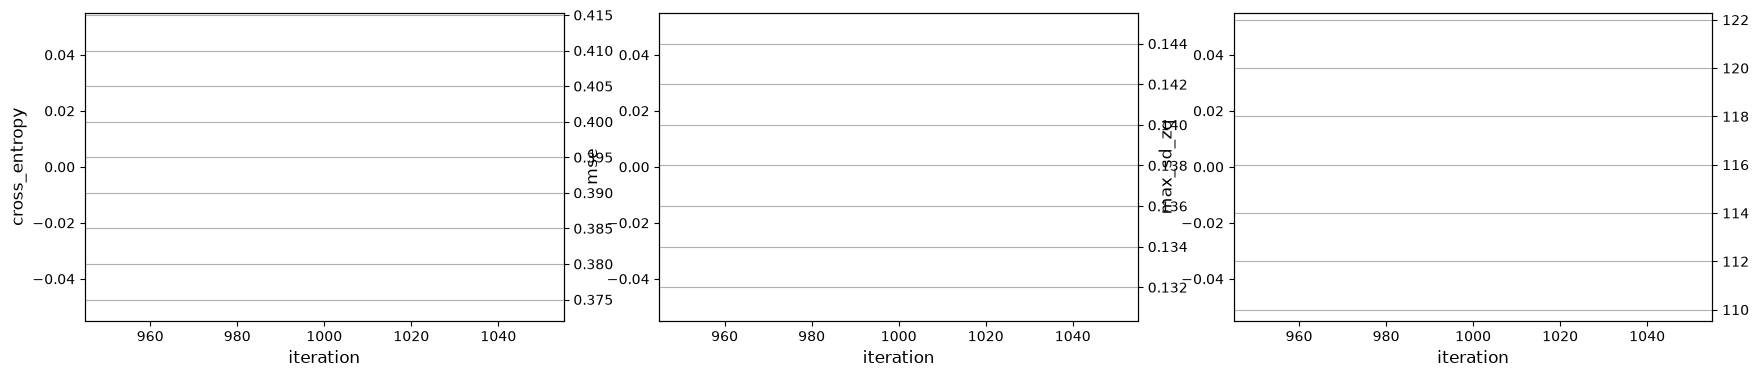

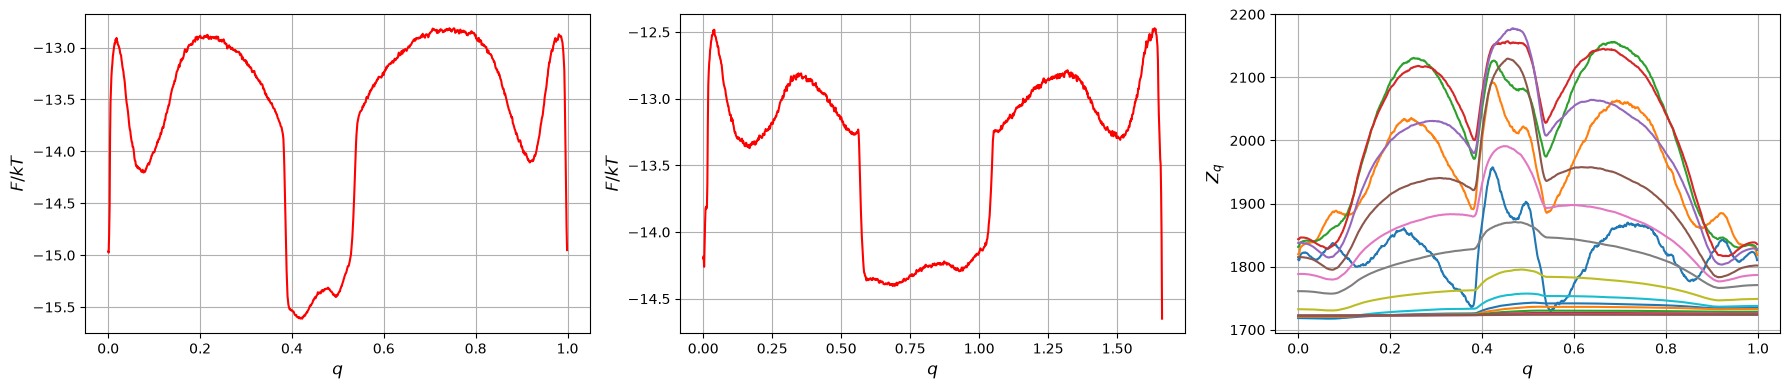

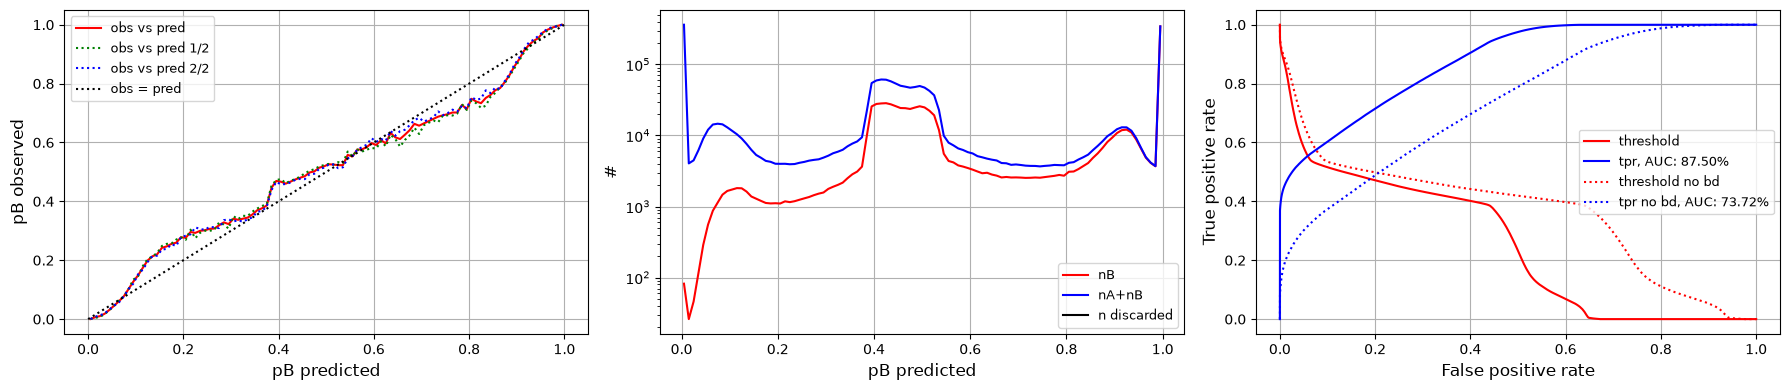

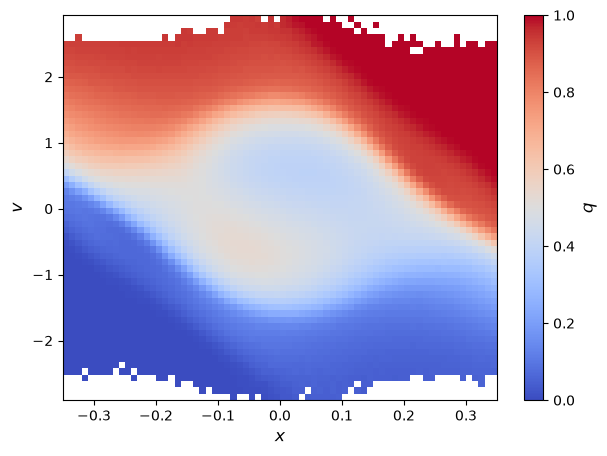

seed 1, 1000 iterations (warm-up: envelope 1, gamma 0.1) RMS(fit - reference) 0.0619
#=2000, xent=0.389331, mse=0.136374, sdzq=44.0396, dzq=155.53, dr2=3465.89, auc=0.877318, |dx|=0.0313202, time=5.7745
#=3000, xent=0.388848, mse=0.136191, sdzq=34.3003, dzq=117.992, dr2=3487.87, auc=0.877767, |dx|=0.00675748, time=11.5605
#=4000, xent=0.388668, mse=0.136123, sdzq=24.3737, dzq=79.6872, dr2=3495.34, auc=0.877974, |dx|=0.00525381, time=17.3409
#=5000, xent=0.388397, mse=0.136001, sdzq=18.886, dzq=64.4246, dr2=3498.4, auc=0.878151, |dx|=0.00412541, time=23.1252
#=6000, xent=0.388415, mse=0.135973, sdzq=16.6763, dzq=57.8086, dr2=3502.05, auc=0.878229, |dx|=0.00191685, time=28.9077
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/history_x5/seed1/it6000 ---


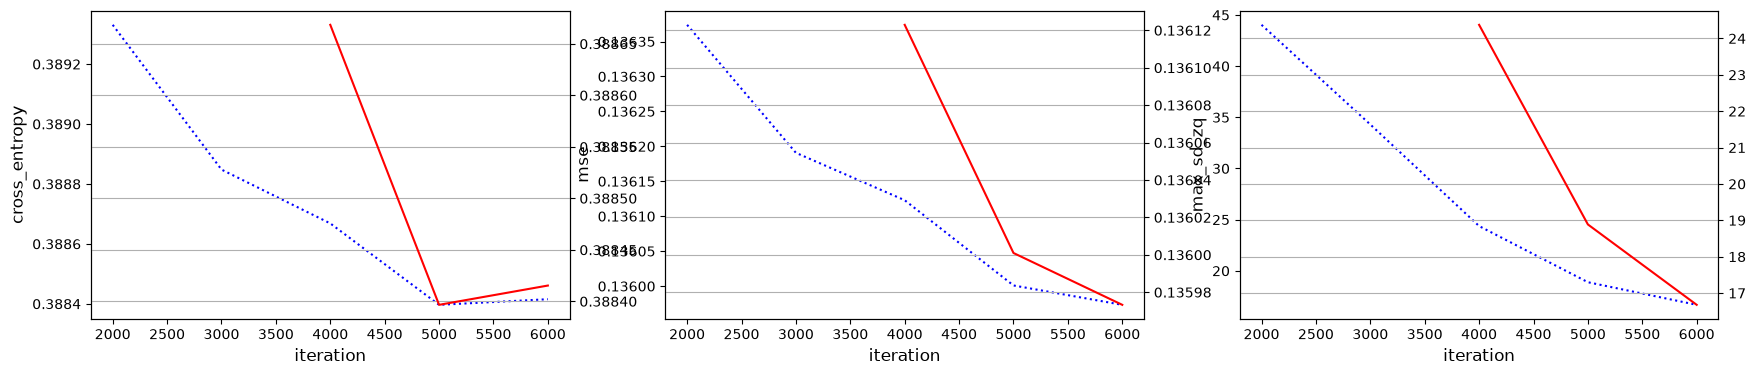

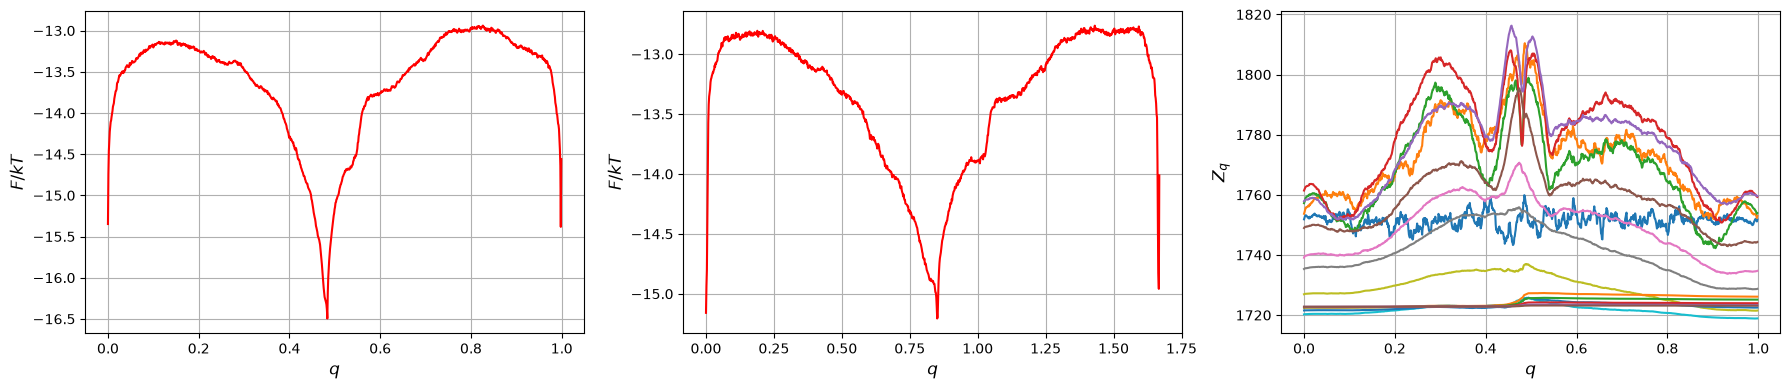

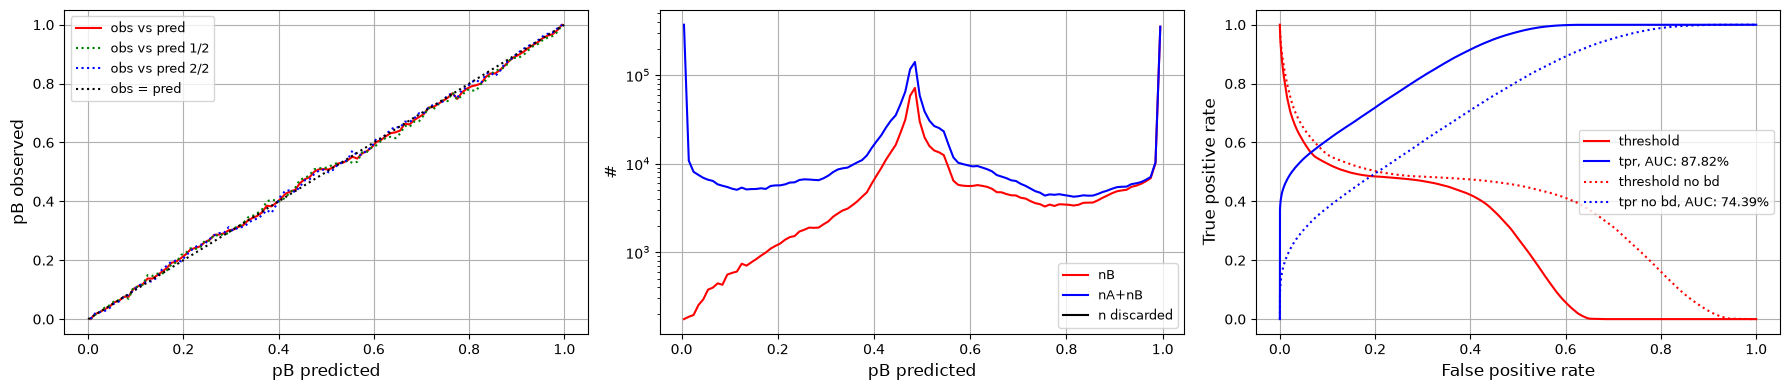

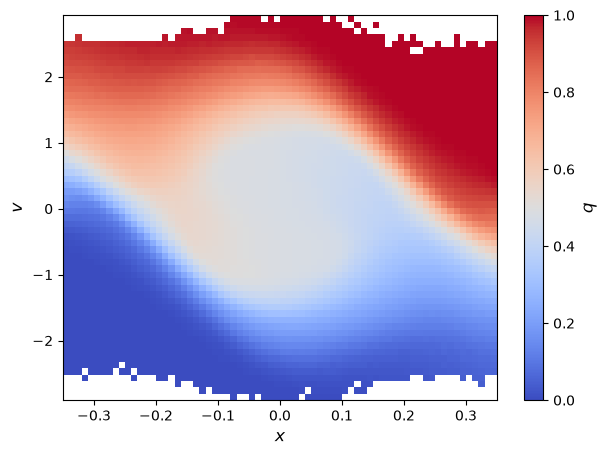

seed 1, 6000 iterations (main: envelope 0.01, gamma 0.1) RMS(fit - reference) 0.0283
#=7000, xent=0.388309, mse=0.13597, sdzq=15.4692, dzq=55.1287, dr2=3496.37, auc=0.878263, |dx|=0.00184969, time=5.77367
#=8000, xent=0.388235, mse=0.135949, sdzq=14.1674, dzq=51.529, dr2=3495.29, auc=0.878334, |dx|=0.00118352, time=11.5601
#=9000, xent=0.388176, mse=0.135927, sdzq=14.6357, dzq=53.3665, dr2=3491.53, auc=0.87836, |dx|=0.00145743, time=17.3405
#=10000, xent=0.388179, mse=0.135903, sdzq=13.1298, dzq=48.6746, dr2=3493.9, auc=0.878424, |dx|=0.00128732, time=23.1256
#=11000, xent=0.388156, mse=0.135908, sdzq=12.6797, dzq=48.3237, dr2=3494.02, auc=0.878426, |dx|=0.000897229, time=28.9078
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/history_x5/seed1/it11000 ---


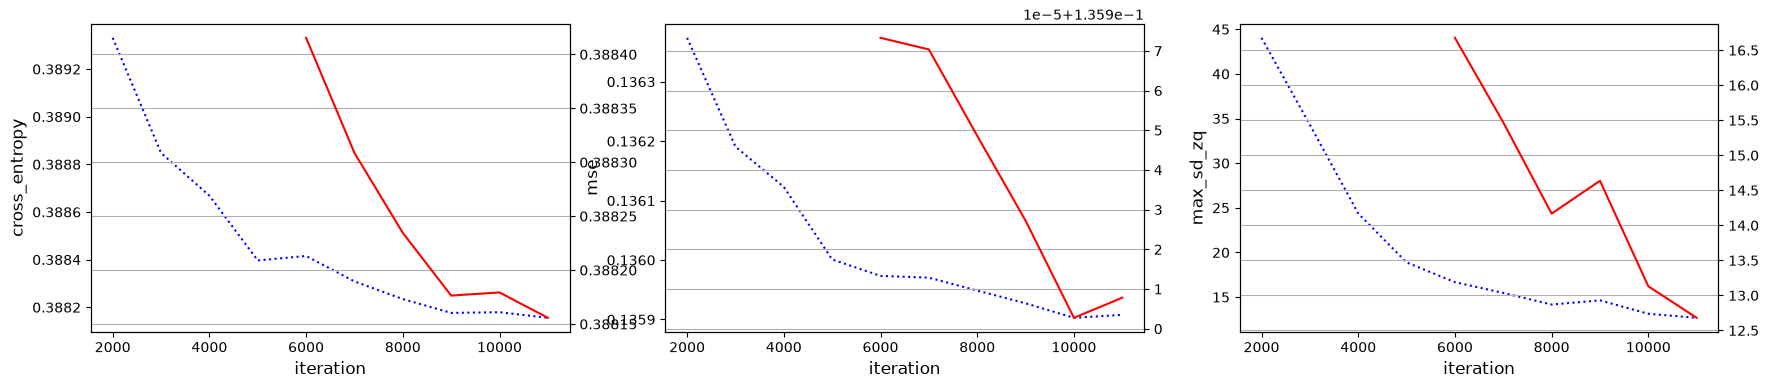

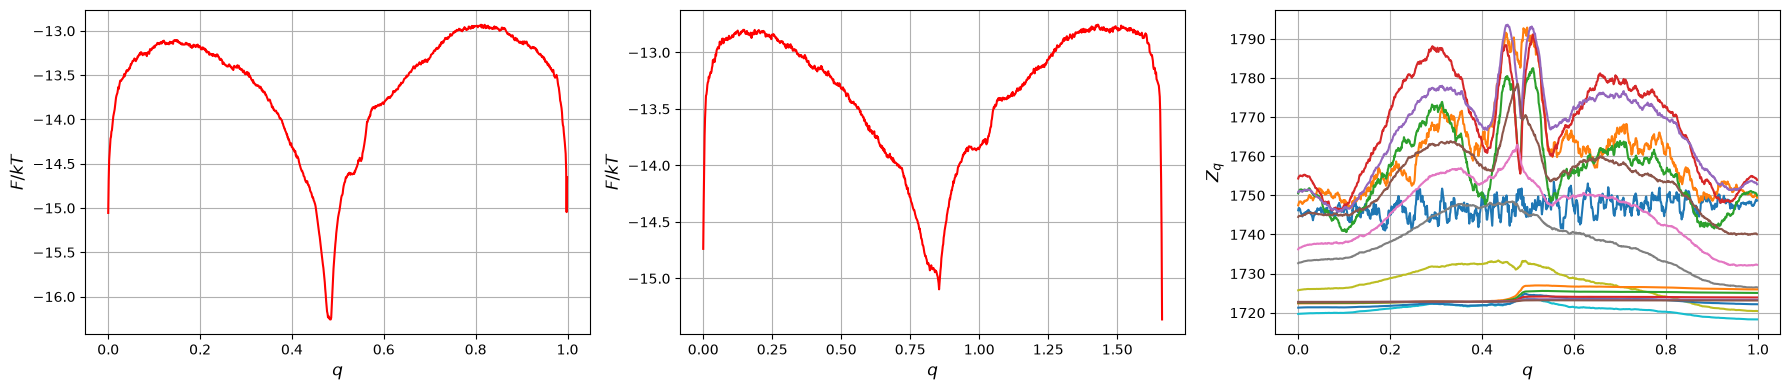

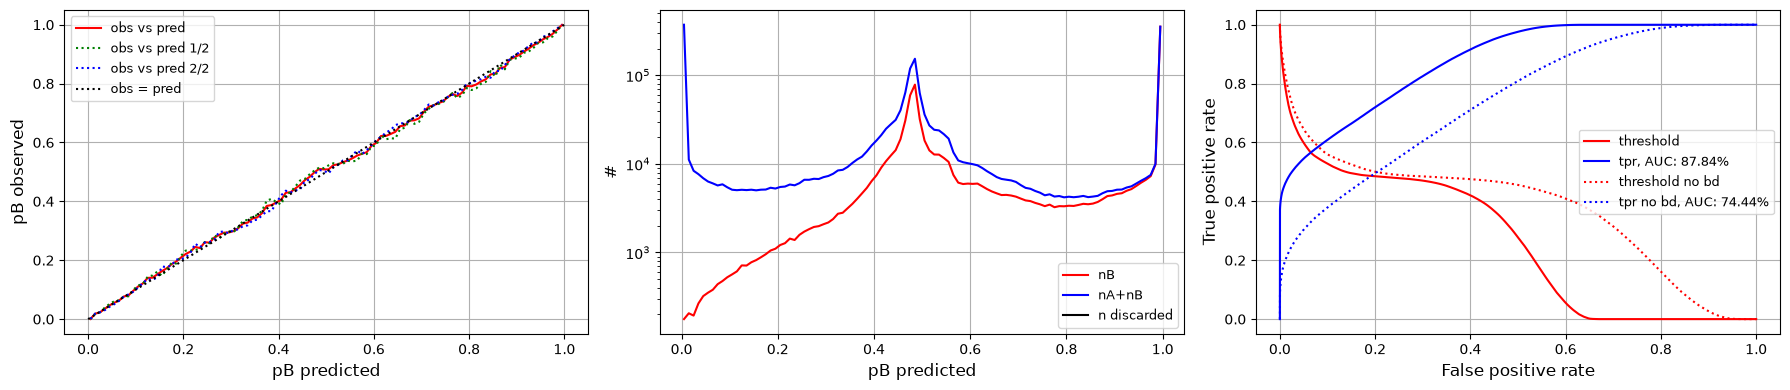

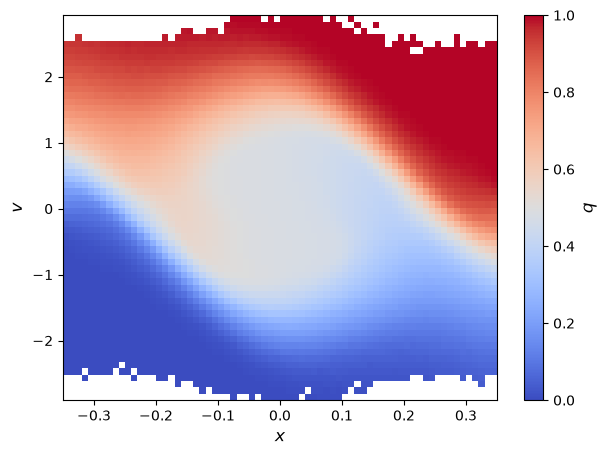

seed 1, 11000 iterations (main: envelope 0.01, gamma 0.1) RMS(fit - reference) 0.0268
#=1000, xent=0.392747, mse=0.137489, sdzq=125.424, dzq=411.088, dr2=3659.21, auc=0.875083, |dx|=0.200122, time=5.80557
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/history_x5/seed2/it1000 ---


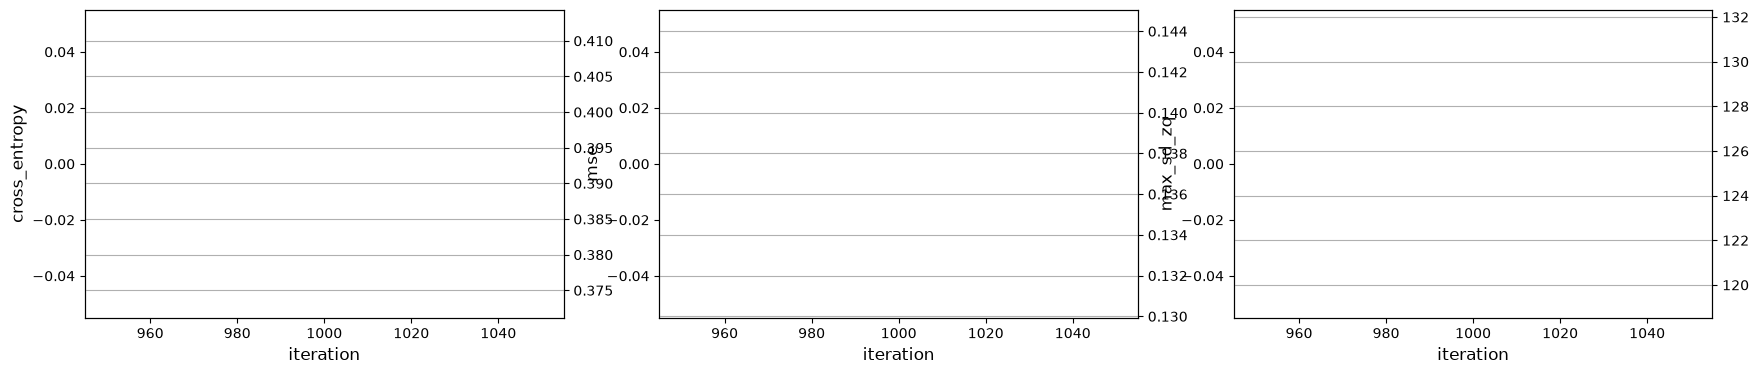

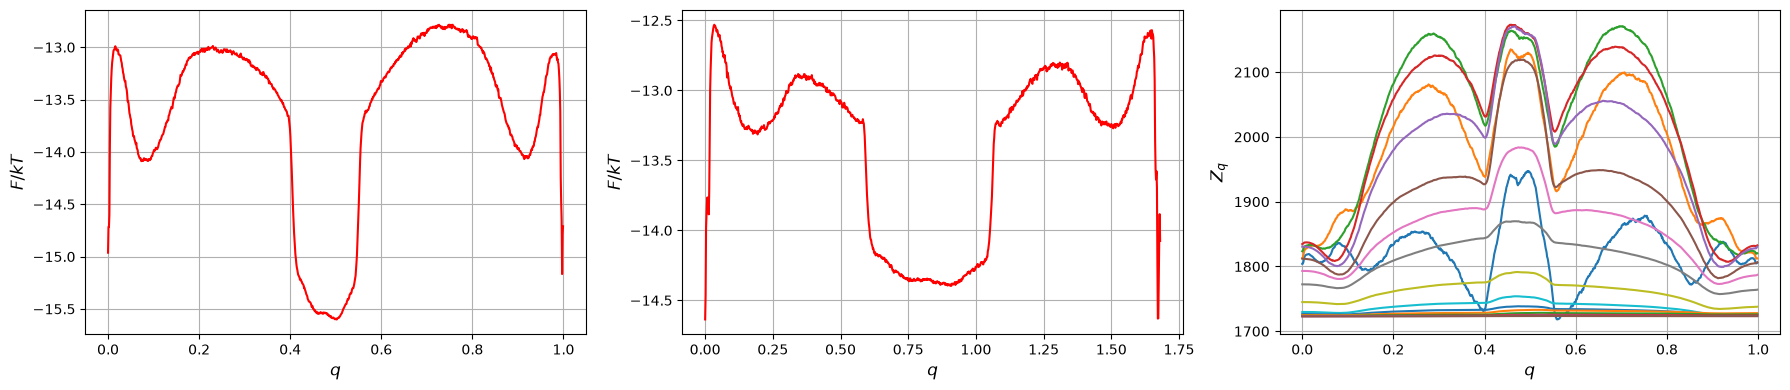

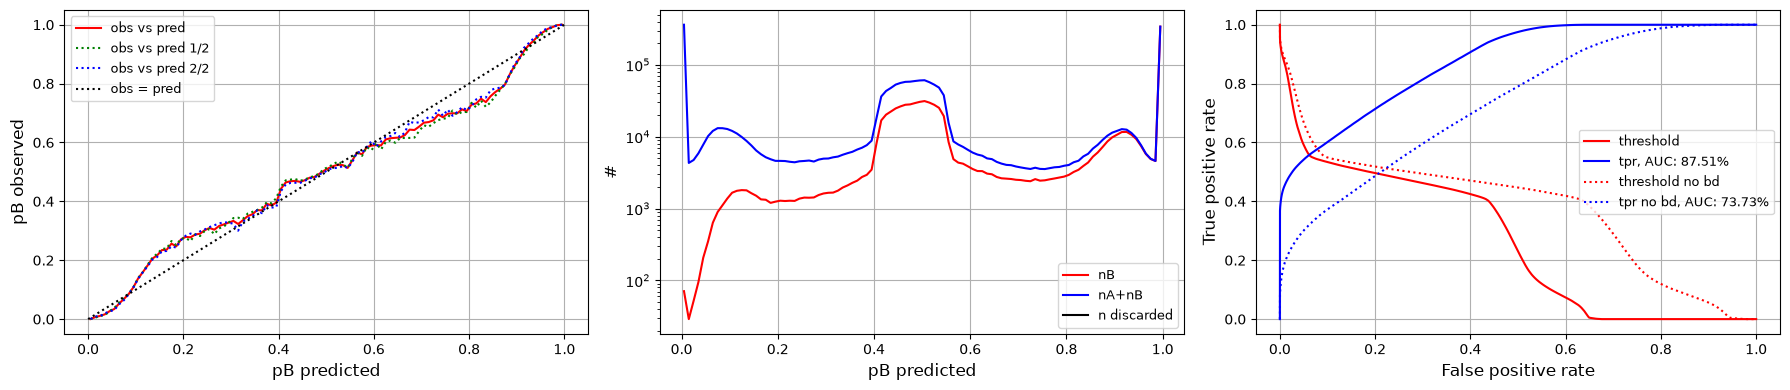

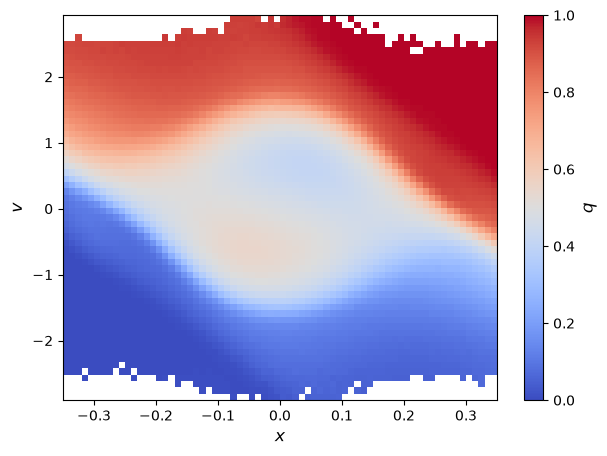

seed 2, 1000 iterations (warm-up: envelope 1, gamma 0.1) RMS(fit - reference) 0.0552
#=2000, xent=0.388981, mse=0.136201, sdzq=50.7579, dzq=170.19, dr2=3442.54, auc=0.877911, |dx|=0.0312485, time=5.77613
#=3000, xent=0.388643, mse=0.136055, sdzq=31.5351, dzq=104.328, dr2=3481.36, auc=0.878103, |dx|=0.0079608, time=11.5565
#=4000, xent=0.388361, mse=0.135958, sdzq=24.8562, dzq=81.006, dr2=3493.95, auc=0.878291, |dx|=0.00446789, time=17.3373
#=5000, xent=0.388248, mse=0.135924, sdzq=18.8904, dzq=67.2686, dr2=3489.37, auc=0.878379, |dx|=0.00297245, time=23.106
#=6000, xent=0.388283, mse=0.135913, sdzq=16.9379, dzq=58.5245, dr2=3495.85, auc=0.878411, |dx|=0.00164895, time=28.8862
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/history_x5/seed2/it6000 ---


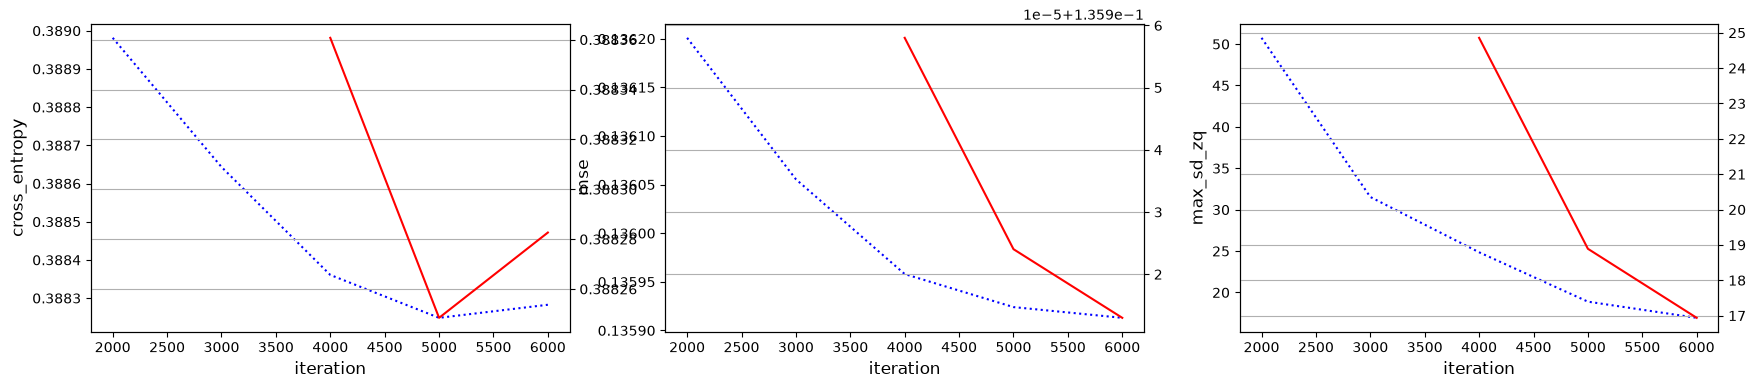

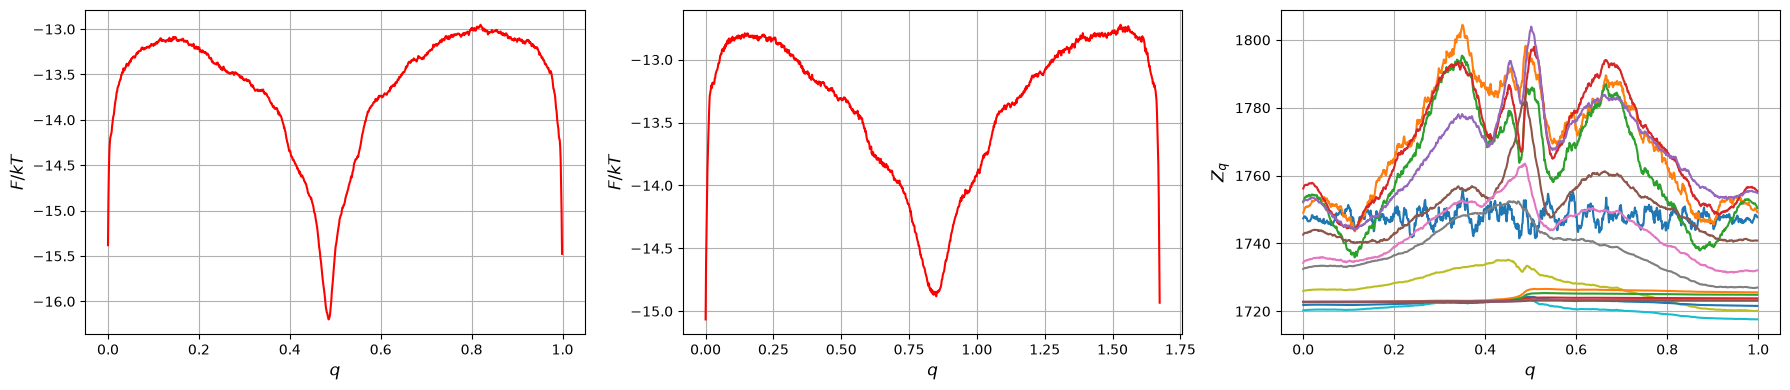

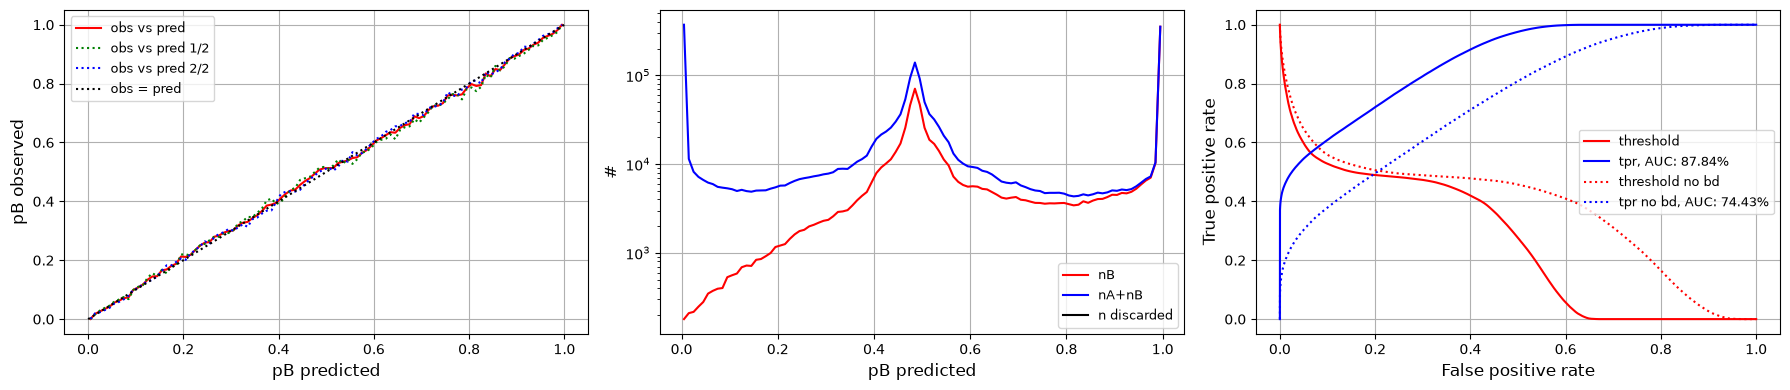

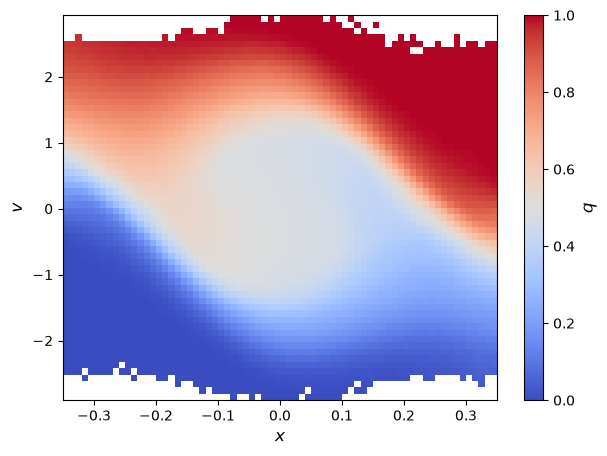

seed 2, 6000 iterations (main: envelope 0.01, gamma 0.1) RMS(fit - reference) 0.0273
#=7000, xent=0.388242, mse=0.13593, sdzq=14.7418, dzq=51.8241, dr2=3497.37, auc=0.878406, |dx|=0.00228816, time=5.77918
#=8000, xent=0.388184, mse=0.135897, sdzq=13.653, dzq=46.3894, dr2=3498.77, auc=0.878446, |dx|=0.00174403, time=11.5622
#=9000, xent=0.388188, mse=0.135909, sdzq=13.1654, dzq=43.9612, dr2=3499.37, auc=0.878451, |dx|=0.00135929, time=17.3446
#=10000, xent=0.388115, mse=0.135884, sdzq=12.5001, dzq=44.397, dr2=3494.82, auc=0.878487, |dx|=0.00146469, time=23.125
#=11000, xent=0.388125, mse=0.135885, sdzq=12.844, dzq=44.28, dr2=3496.53, auc=0.878506, |dx|=0.00108618, time=28.9136
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/history_x5/seed2/it11000 ---


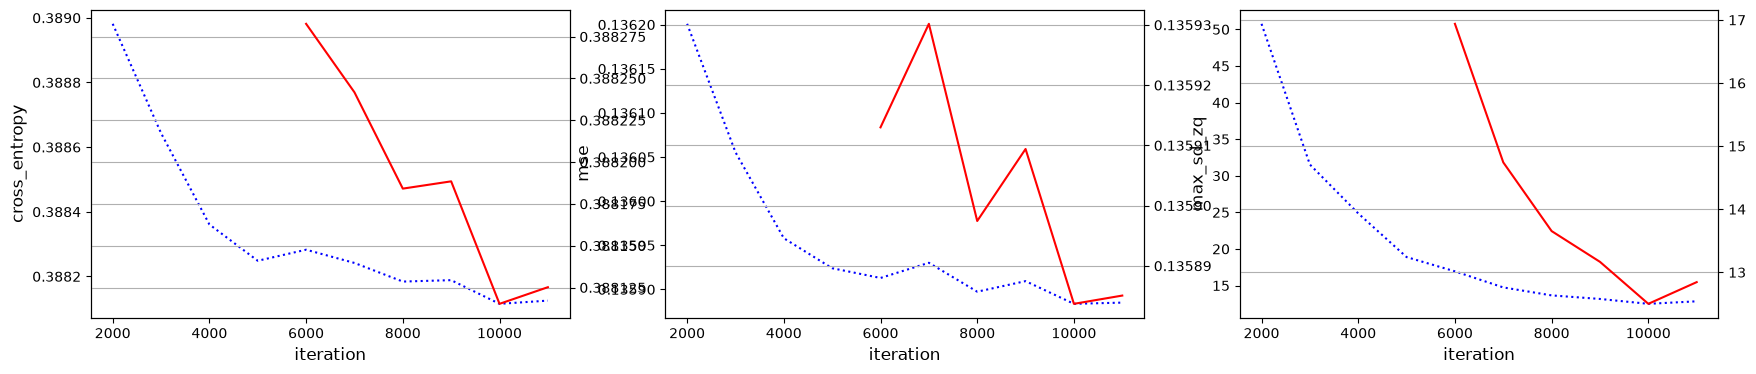

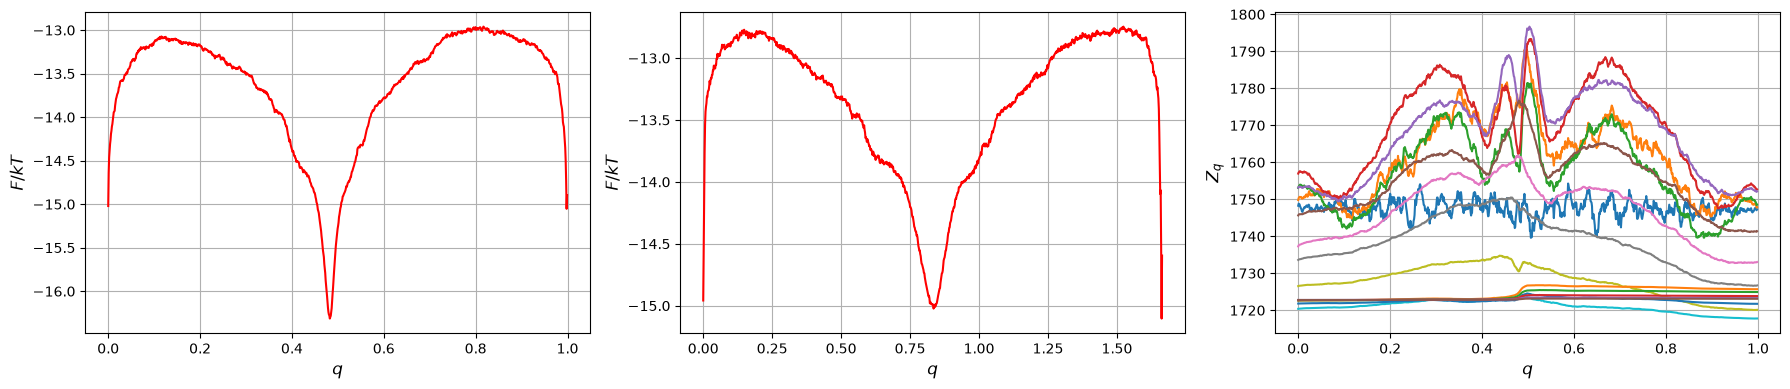

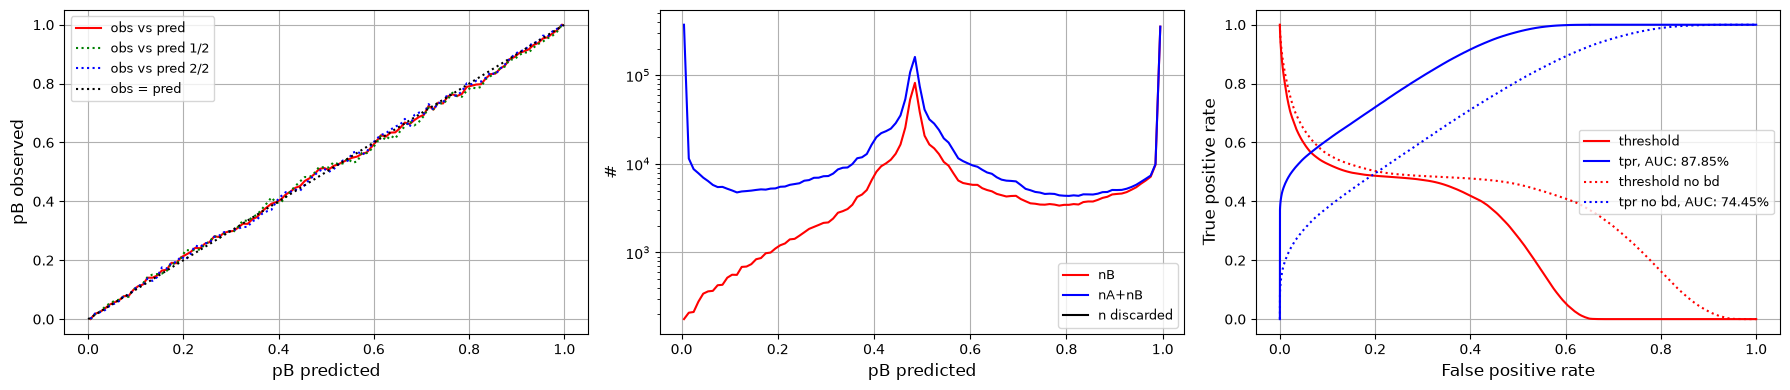

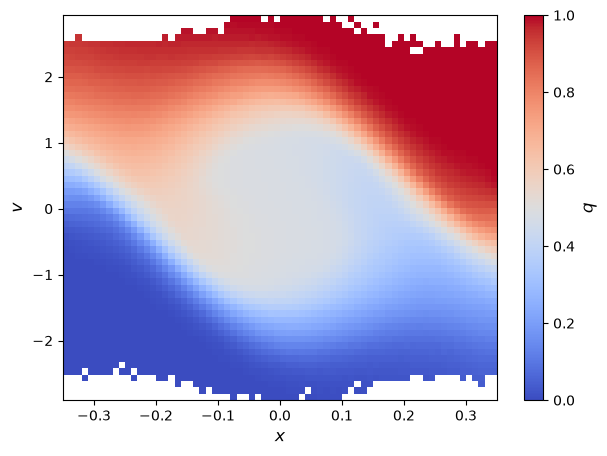

seed 2, 11000 iterations (main: envelope 0.01, gamma 0.1) RMS(fit - reference) 0.0261
#=1000, xent=0.393177, mse=0.137587, sdzq=149.83, dzq=434.883, dr2=3608.41, auc=0.87616, |dx|=0.201516, time=5.79876
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/history_x5/seed3/it1000 ---


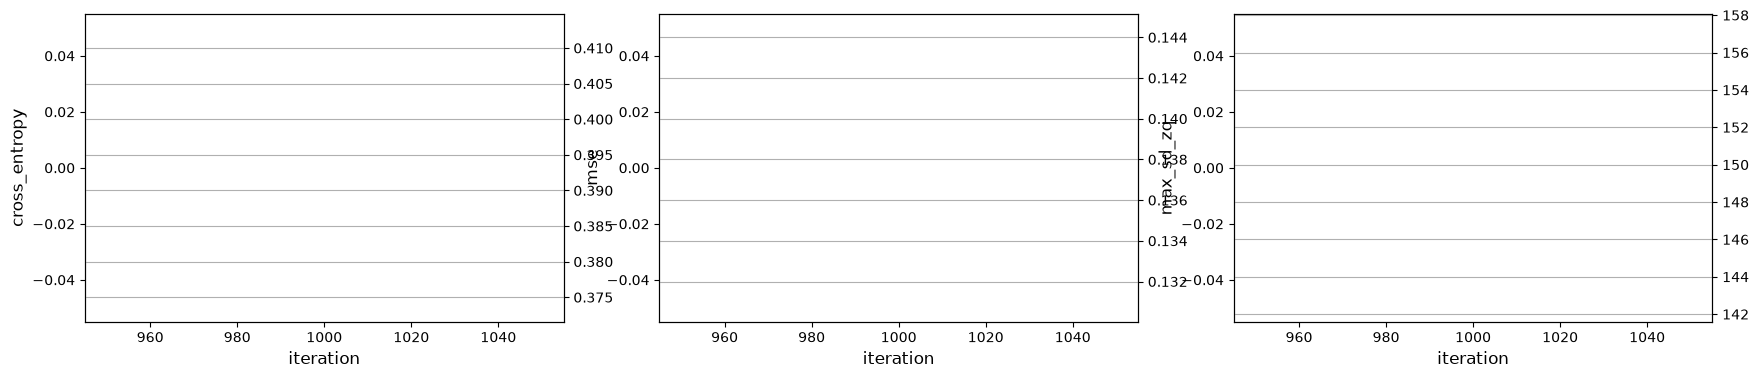

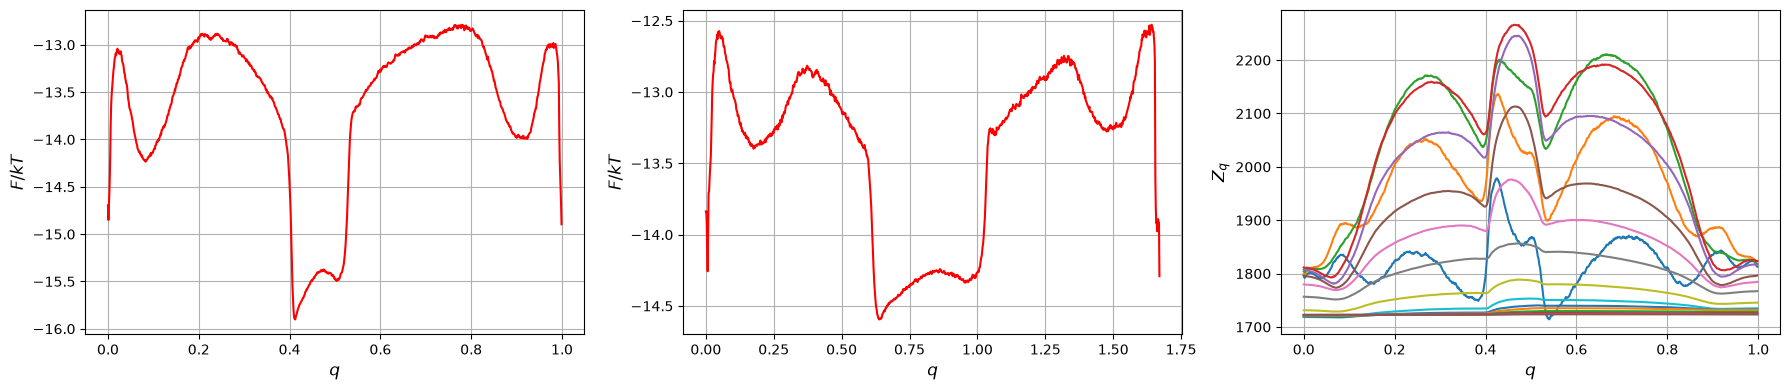

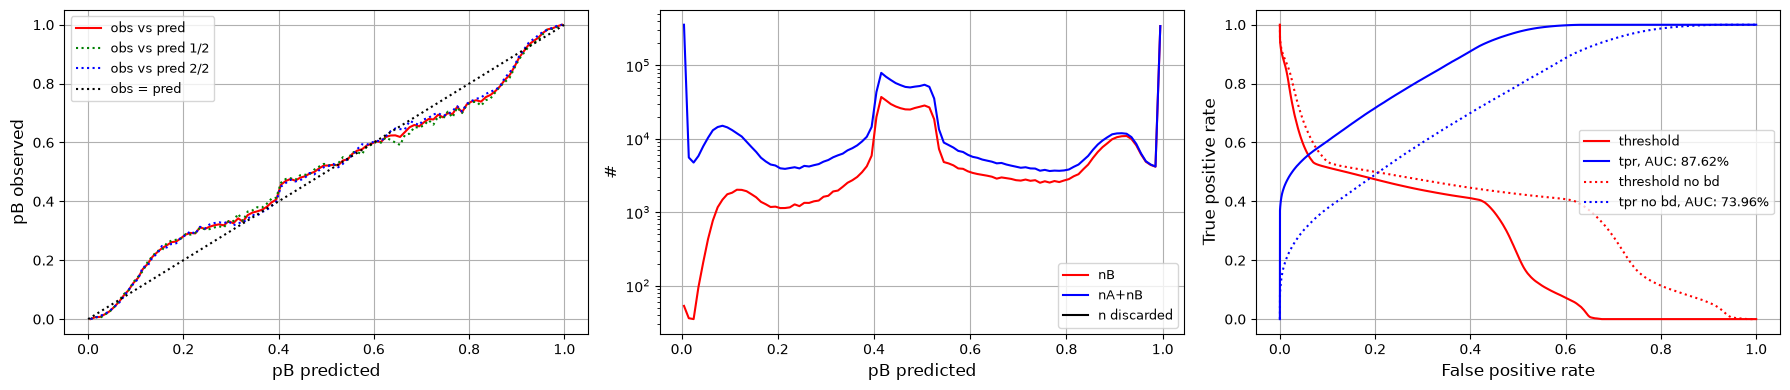

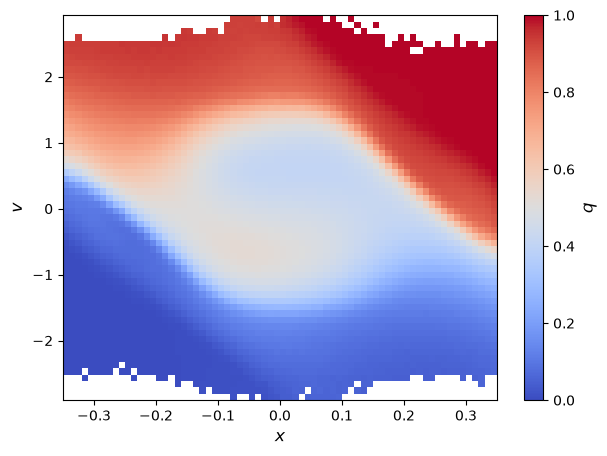

seed 3, 1000 iterations (warm-up: envelope 1, gamma 0.1) RMS(fit - reference) 0.0578
#=2000, xent=0.389503, mse=0.136396, sdzq=56.2023, dzq=182.529, dr2=3466.17, auc=0.877738, |dx|=0.0290007, time=5.79233
#=3000, xent=0.388842, mse=0.136193, sdzq=41.5264, dzq=134.887, dr2=3479.38, auc=0.877876, |dx|=0.00862835, time=11.5876
#=4000, xent=0.388477, mse=0.136037, sdzq=29.4013, dzq=105.429, dr2=3483.25, auc=0.8781, |dx|=0.00487812, time=17.3802
#=5000, xent=0.388288, mse=0.135962, sdzq=25.0459, dzq=95.9586, dr2=3483.98, auc=0.87826, |dx|=0.00298597, time=23.1716
#=6000, xent=0.388188, mse=0.135915, sdzq=21.8396, dzq=84.5787, dr2=3489.13, auc=0.878372, |dx|=0.00213171, time=28.9588
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/history_x5/seed3/it6000 ---


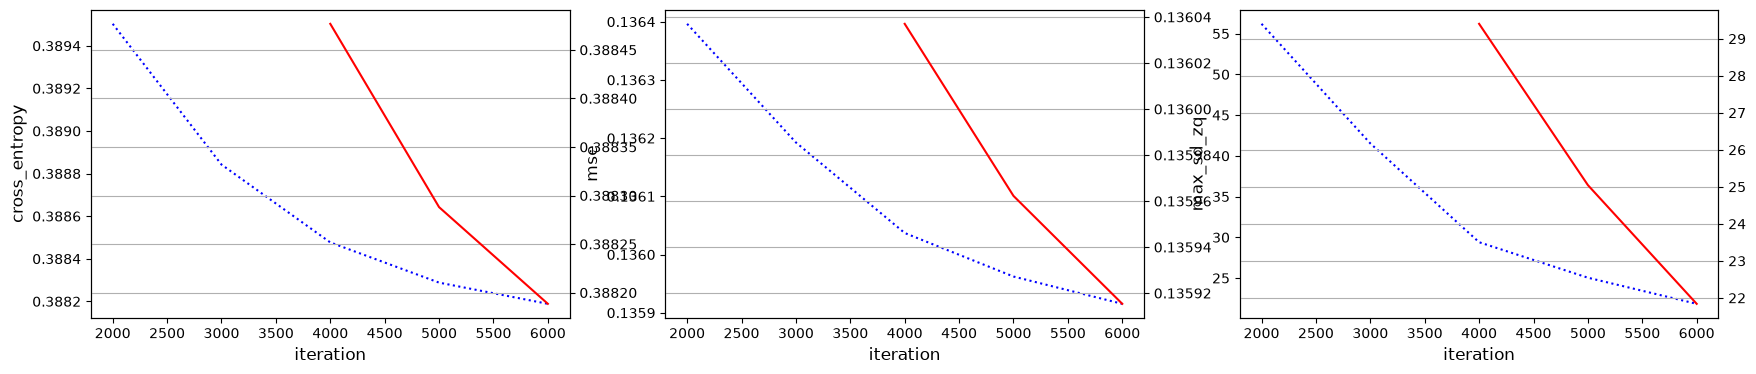

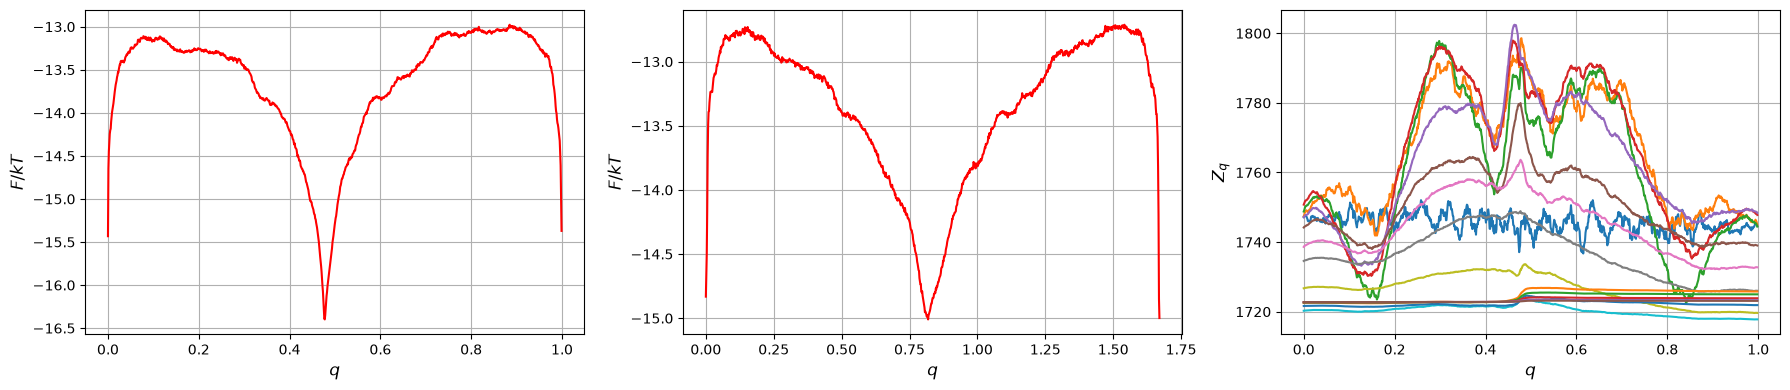

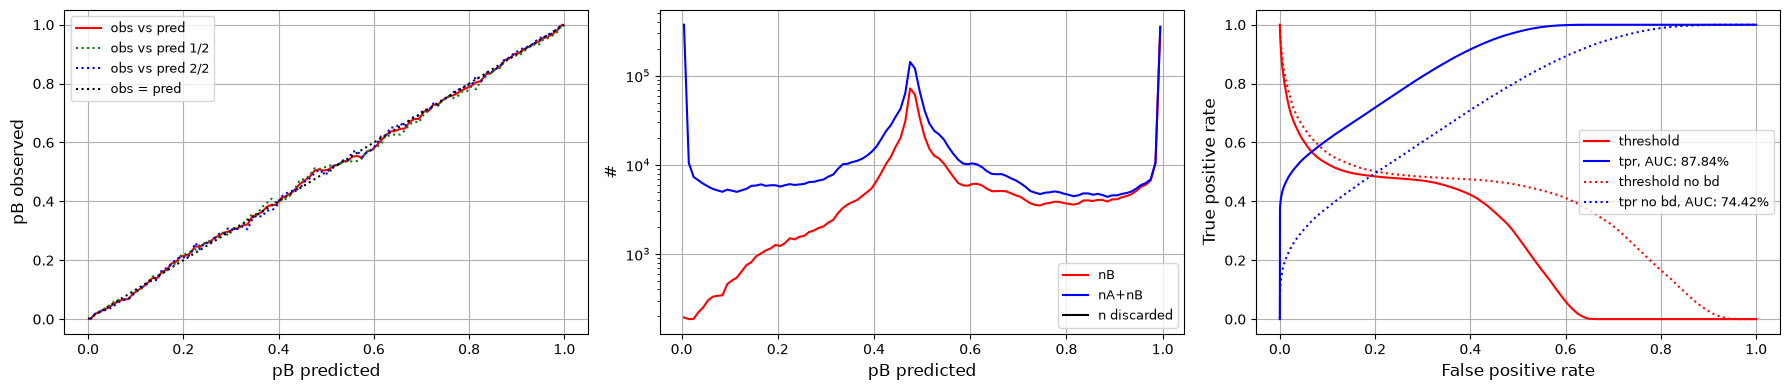

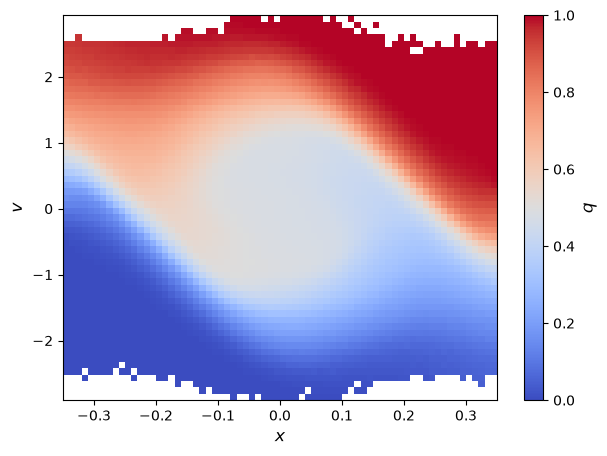

seed 3, 6000 iterations (main: envelope 0.01, gamma 0.1) RMS(fit - reference) 0.0264
#=7000, xent=0.388108, mse=0.135897, sdzq=19.4095, dzq=77.5454, dr2=3497.55, auc=0.878408, |dx|=0.00158626, time=5.78142
#=8000, xent=0.388119, mse=0.135897, sdzq=17.8302, dzq=72.2624, dr2=3493.31, auc=0.878427, |dx|=0.00122936, time=11.5666
#=9000, xent=0.388101, mse=0.135885, sdzq=16.5154, dzq=66.7022, dr2=3490.97, auc=0.878462, |dx|=0.00105487, time=17.3577
#=10000, xent=0.38807, mse=0.135877, sdzq=15.7348, dzq=63.0927, dr2=3490.3, auc=0.878494, |dx|=0.000804276, time=23.1479
#=11000, xent=0.388059, mse=0.135867, sdzq=15.6227, dzq=61.7773, dr2=3489.71, auc=0.87851, |dx|=0.00076086, time=28.9388
--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/history_x5/seed3/it11000 ---


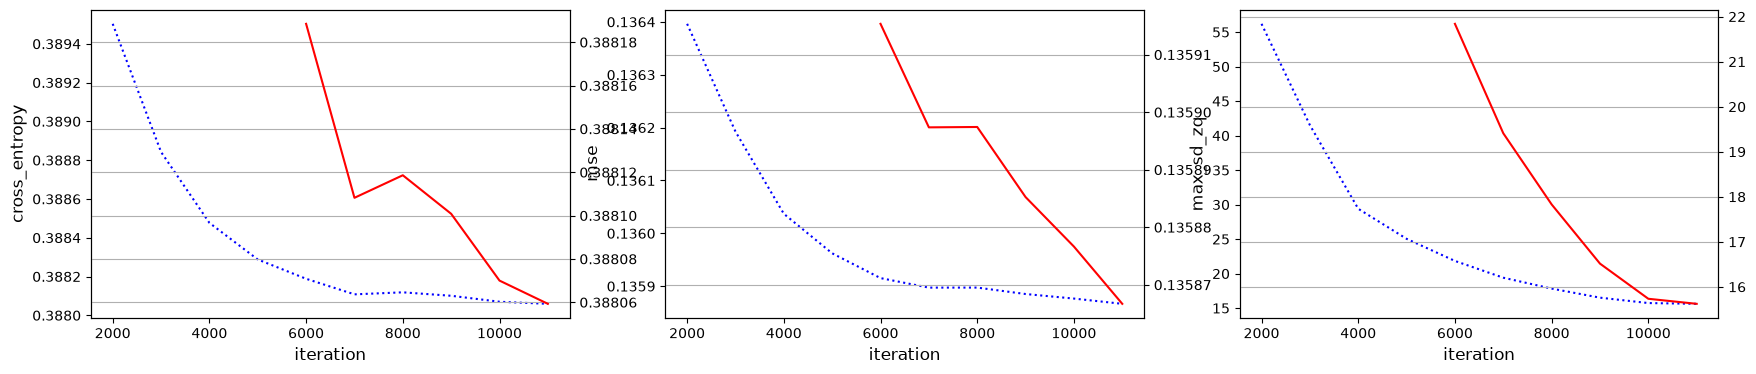

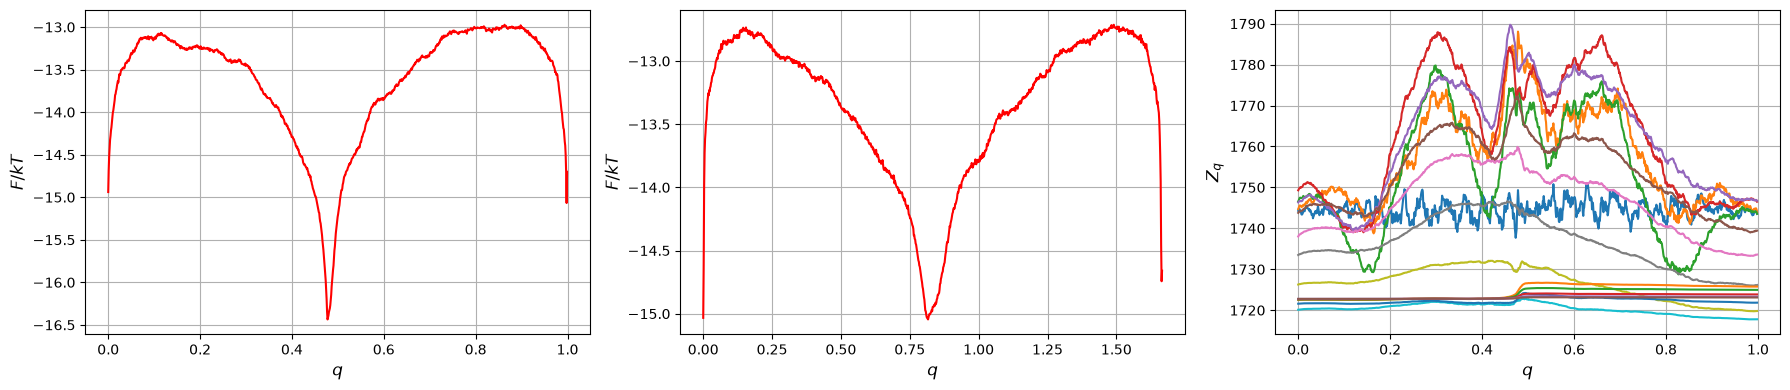

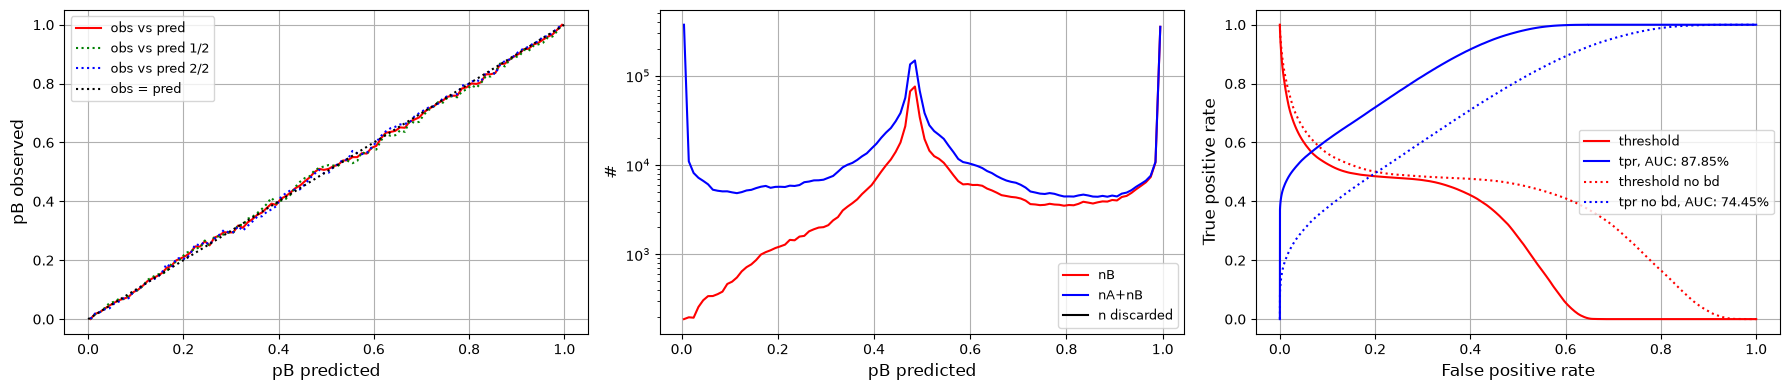

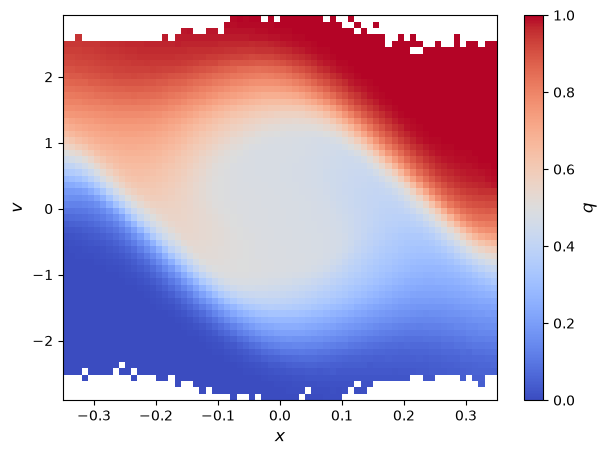

seed 3, 11000 iterations (main: envelope 0.01, gamma 0.1) RMS(fit - reference) 0.0254
seed 1: RMS(fit - reference) 0.0268
seed 2: RMS(fit - reference) 0.0261
seed 3: RMS(fit - reference) 0.0254


({1: {'r': array([0.70292786, 0.68429248, 0.68142133, ..., 0.34094686, 0.37468964,
          0.43310036], shape=(2000000,)),
   'report': 'RMS(fit - reference) 0.0268'},
  2: {'r': array([0.47075295, 0.42739232, 0.42638961, ..., 0.34074875, 0.37444037,
          0.43870801], shape=(2000000,)),
   'report': 'RMS(fit - reference) 0.0261'},
  3: {'r': array([0.70900662, 0.65199358, 0.65959079, ..., 0.3413329 , 0.37441977,
          0.43315178], shape=(2000000,)),
   'report': 'RMS(fit - reference) 0.0254'}},
 <optimalrcs.CommittorNE at 0x7fe589bf5350>)

In [12]:
run_variant('history_x5', [0], [0,1,2,4], MAX_ITER_HIST)

### 5c. Subsampled fit, histories on the fine grid

Does a history on the *fine* grid recover the velocity when the fit itself only sees the trajectory every `SUB` frames? The update solves the NPNEq equations at lag `SUB`, from every `SUB`-th frame (`fit_transform(..., delta_t=SUB, delta_t_stride=SUB)`): the transitions are those of the subsampled trajectory, t → min(t + `SUB`, first frame in A or B), so entries into A or B between the subsampled frames still stop the transition. The basis is evaluated on all frames, so `history_delta_t` counts fine frames:

| variant | CVs | history | what it sees at t |
|---|---|---|---|
| `sub<SUB>_hist_fine` | x | 0, 1 | x(t), x(t−1): the half-step velocity (x(t) − x(t−1))/dt |
| `sub<SUB>_hist_coarse` | x | 0, `SUB` | x(t), x(t−`SUB`): what the subsampled trajectory itself has |
| `sub<SUB>_x_v` | x, v | none | the recorded velocity: the ceiling |

The committor is a martingale at every lag given the whole past, so the lag-`SUB` equations hold for any basis built from the past, also from frames between the subsampled ones. Expected: fine ≈ x_v at every `SUB`; coarse falls behind once `SUB` is long enough that x(t) − x(t−`SUB`) is no longer a good estimate of v(t) (force changes over `SUB` frames, friction and noise). The metrics printed during the fit use all frames at lag 1.

In [ ]:
SUB = 10                         # fit lag and stride, in frames
SUB_VARIANTS = {                 # name: (CV columns of (x, v), history lags in fine frames or None)
    f'sub{SUB}_hist_fine': ([0], [0, 1]),
    f'sub{SUB}_hist_coarse': ([0], [0, SUB]),
    f'sub{SUB}_x_v': ([0, 1], None),
}
MAX_ITER_SUB = MAX_ITER_HIST

for variant, (cv_cols, history) in SUB_VARIANTS.items():
    Y = cp.asarray(np.c_[lam, v * V_SCALE][:, cv_cols])
    kw = dict(ny=NY, gamma=GAMMA, print_step=min(CHUNK, 1000), save_min_delta_zq=False, lazy_basis=True,
              delta_t=SUB, delta_t_stride=SUB)
    if history:
        kw.update(history_delta_t=list(history), history_type='y(t-d),y(t)', history_shift_type='r(t)')
    fits[variant] = {}
    for seed in SEEDS:
        np.random.seed(seed); cp.random.seed(seed)
        q = make_q()
        comp_y = lambda: Y[:, np.random.randint(Y.shape[1])]
        t = time.time()
        stages = [(WARMUP_ITER, WARMUP_ENVELOPE)] + [(CHUNK, ENVELOPE)] * (MAX_ITER_SUB // CHUNK)
        done = 0
        for n_it, env in stages:
            optimalrcs.envelope_scale = env
            q.fit_transform(comp_y, max_iter=n_it - 1, **kw)
            done += n_it
            print(f'{variant}, seed {seed}: {done} iterations (envelope {env}), {(time.time() - t) / 60:.1f} min, '
                  f'{len(q._lag_t0)} transitions. {report(q)}', flush=True)
        r = cp.asnumpy(q.r_traj)
        fits[variant][seed] = {'r': r, 'report': report(q)}
        os.makedirs(f'{OUT}/{variant}/seed{seed}', exist_ok=True)
        np.save(f'{OUT}/{variant}/seed{seed}/q_traj.npy', r.astype(np.float32))
        fig = qv_map(q); fig.axes[0].set_title(f'{variant}, seed {seed}')
        fig.savefig(f'{OUT}/{variant}/seed{seed}/q_x_v.png', dpi=110); plt.show()
        del q; cp.get_default_memory_pool().free_all_blocks()

## 6. Results

Per variant and seed: the metrics at the end and, with a reference, the RMS of fit − reference over the frames between A and B. Then q along x and in the (x, v) plane (mean per bin), with the reference next to it if given.

final  rms_free
variant    seed                                       
x_v        1     RMS(fit - reference) 0.0179  0.017938
           2     RMS(fit - reference) 0.0437  0.043687
           3     RMS(fit - reference) 0.0457  0.045730
history_x5 1     RMS(fit - reference) 0.0268  0.026797
           2     RMS(fit - reference) 0.0261  0.026090
           3     RMS(fit - reference) 0.0254  0.025444

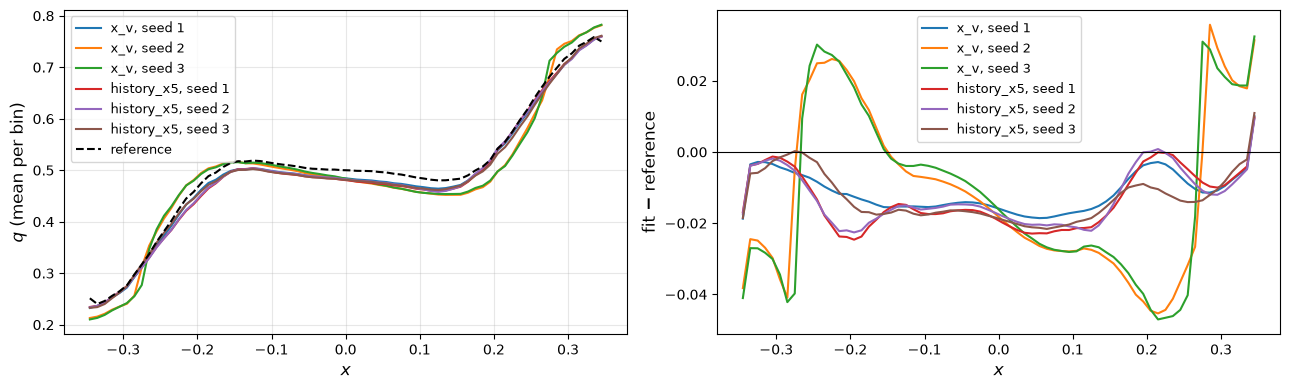

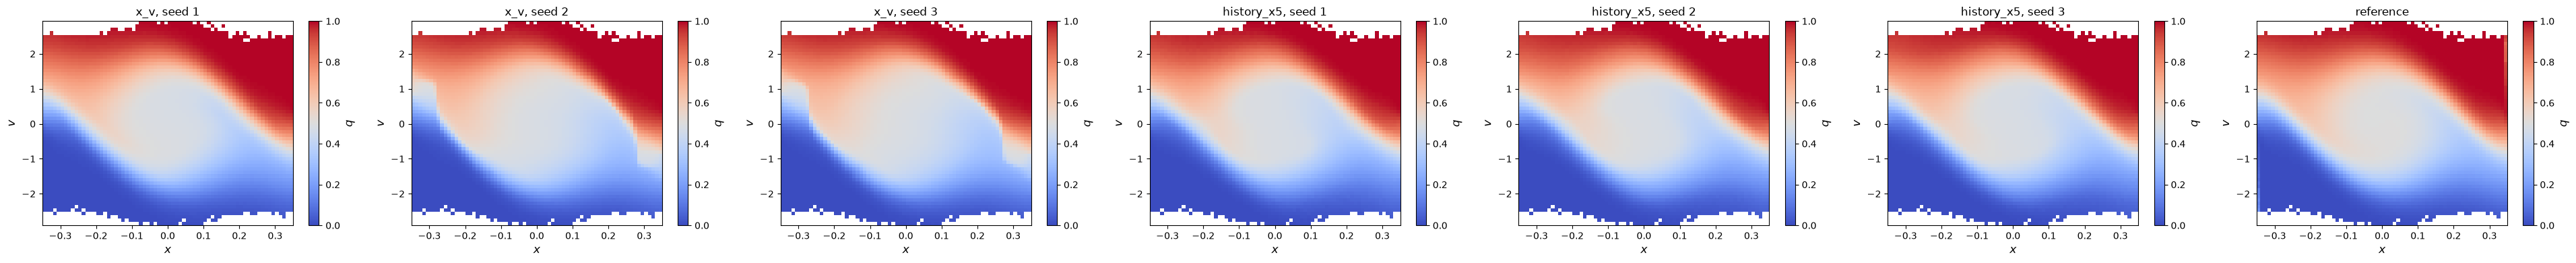

In [13]:
rows = []
for variant, res in fits.items():
    for s, rr in res.items():
        r = rr['r']
        row = dict(variant=variant, seed=s, final=rr.get('report') or None)
        if q_exact is not None:
            row['rms_free'] = np.sqrt(np.mean((r[free] - q_exact[free]) ** 2))
        rows.append(row)
import pandas as pd
display(pd.DataFrame(rows).set_index(['variant', 'seed']))

mid = (edges_l[1:] + edges_l[:-1]) / 2
bi = np.clip(np.digitize(lam, edges_l) - 1, 0, len(mid) - 1)
nb = np.bincount(bi[free], minlength=len(mid))
mean_q = lambda r: np.bincount(bi[free], r[free], len(mid)) / np.maximum(nb, 1)
fig, axes = plt.subplots(1, 2 if q_exact is not None else 1, figsize=(13 if q_exact is not None else 7, 4), squeeze=False)
for variant, res in fits.items():
    for s, rr in res.items():
        axes[0, 0].plot(mid, mean_q(rr['r']), label=f'{variant}, seed {s}')
        if q_exact is not None:
            axes[0, 1].plot(mid, mean_q(rr['r']) - mean_q(q_exact), label=f'{variant}, seed {s}')
if q_exact is not None:
    axes[0, 0].plot(mid, mean_q(q_exact), 'k--', label='reference')
    axes[0, 1].axhline(0, color='k', lw=0.8); axes[0, 1].set(xlabel='$x$', ylabel='fit $-$ reference'); axes[0, 1].legend()
axes[0, 0].set(xlabel='$x$', ylabel='$q$ (mean per bin)'); axes[0, 0].legend(); axes[0, 0].grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f'{OUT}/profiles.png', dpi=110); plt.show()

panels = [(f'{variant}, seed {s}', rr['r']) for variant, res in fits.items() for s, rr in res.items()]
if q_exact is not None:
    panels.append(('reference', q_exact))
fig, axes = plt.subplots(1, len(panels), figsize=(5.5 * len(panels), 4), squeeze=False)
for ax, (title, r) in zip(axes[0], panels):
    s_ = np.histogram2d(lam[free], v[free], [edges_l, edges_v], weights=r[free])[0]
    im = ax.pcolormesh(edges_l, edges_v, np.where(n_lv > 20, s_ / np.maximum(n_lv, 1), np.nan).T, cmap='coolwarm', vmin=0, vmax=1)
    ax.set(title=title, xlabel='$x$', ylabel='$v$'); fig.colorbar(im, ax=ax, label='$q$')
fig.tight_layout(); fig.savefig(f'{OUT}/q_x_v.png', dpi=110); plt.show()


## 7. Save

The final q per frame of every fit, as `<OUT>/<variant>/seed<s>/q_traj.npy` (written during the fit) and here together in one file.

In [14]:
np.savez(f'{OUT}/fits.npz', lam=lam, v=v, **{f'{variant}_seed{s}': rr['r'] for variant, res in fits.items() for s, rr in res.items()})
print('saved', f'{OUT}/fits.npz')


saved /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/1d_cos_well/infretis_langevin_md/langevin_md_ase_long/fits.npz
